# Process the goggles-left (single-eye) session

Builds the eye-conditioned `MonocularDevice` for the **left-eye** session
`260722_SAM045_goggles-left`, runs `SessionAnalyzer.analyze_session_stats`
and caches `{session_name}_dataframe.pkl` next to the session data (same
pattern as `process-monocular-session.ipynb`), then:

1. plots each **left-reliable** cell's response (`CellVisualizer.make_eye_plot`), and
2. plots the histogram of reliable cells' receptive-field positions (`SessionVisualizer.plot_rf_histograms`).

Run this in its own kernel (`distance-project` env) with **only** `disparity-analysis` on `sys.path`.


In [110]:
import sys, os
import pandas as pd
import matplotlib.pyplot as plt

base_dir = r"C:\Users\acostamendoza\projects\distance-project"
for p in (base_dir, base_dir + r"\disparity-analysis"):
    if p not in sys.path:
        sys.path.append(p)

from src.data.MonocularDevice import MonocularDevice
from src.analysis.CellAnalysis import SessionAnalyzer
from src.viz.SessionVisualizer import SessionVisualizer
from src.viz.CellVisualizer import CellVisualizer

%load_ext autoreload
%autoreload 2

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [111]:
mouse, date, experiment = "SAM045", "260731", "monocular"
M = MonocularDevice(mouse_name=mouse, record_date=date, experiment_name=experiment)
print("session:", M.session_name, "| eyes:", M.present_eyes,
      "| single_eye:", M.single_eye, "| cells:", len(M.suite2p_id))

Creating directory: results
session: 260731_SAM045_monocular | eyes: ['right', 'left'] | single_eye: False | cells: 1417


In [112]:
# load cached stats if present, else compute once (slow) and save the pkl
pkl_path = os.path.join(M.data_dir, f"{M.session_name}_dataframe.pkl")
if os.path.exists(pkl_path):
    stats_df = pd.read_pickle(pkl_path)
    print(f"Loaded cached stats: {pkl_path}")
else:
    stats_df = SessionAnalyzer(M).analyze_session_stats(n_iterations=200)
    SessionAnalyzer(M).save_dataframe(stats_df)
stats_df.head()

Saved DataFrame to: D:/data-distance-coding-project/processed-data\260731_SAM045_monocular\260731_SAM045_monocular_dataframe.pkl


,cell,session_name,right_reliable,right_mean_corr,right_rf,right_rf_value,right_px,left_reliable,left_mean_corr,left_rf,left_rf_value,left_px,ODI
0,0,260731_SAM045_monocular,False,0.372498,29,0.406950,54.613559,True,0.573895,33,0.530497,52.294915,-0.131791
1,1,260731_SAM045_monocular,False,0.396897,27,0.327470,53.067797,False,0.178419,16,0.129061,65.433898,0.434603
2,2,260731_SAM045_monocular,True,0.610141,51,0.580581,71.616949,False,0.318733,33,0.240420,52.294915,0.414325
3,3,260731_SAM045_monocular,False,0.469624,3,0.051431,34.518644,True,0.741478,1,0.869094,77.027119,-0.888256
4,4,260731_SAM045_monocular,False,0.255179,43,0.306091,65.433898,False,0.363119,56,0.358002,34.518644,-0.078169


In [114]:
sv = SessionVisualizer(M, stats_df=stats_df)
sets = sv.print_summary()
# single-eye session -> reliable set is keyed 'reliable'; 'left' if both eyes present
left_reliable = sorted(sets.get("left", sets.get("reliable")))
print(f"{len(left_reliable)} left-reliable cells")

 Session: 260731_SAM045_monocular
 Eyes shown: right, left
 Total cells: 1417
--------------------------------------------------
 Right reliable        :  488  ( 34.4%)
 Left reliable         :  100  (  7.1%)
 Both eyes reliable    :   46  (  3.2%)
--------------------------------------------------
 Right-only            :  442
 Left-only             :   54
 Either eye            :  542  ( 38.2%)
 Neither               :  875  ( 61.8%)
100 left-reliable cells


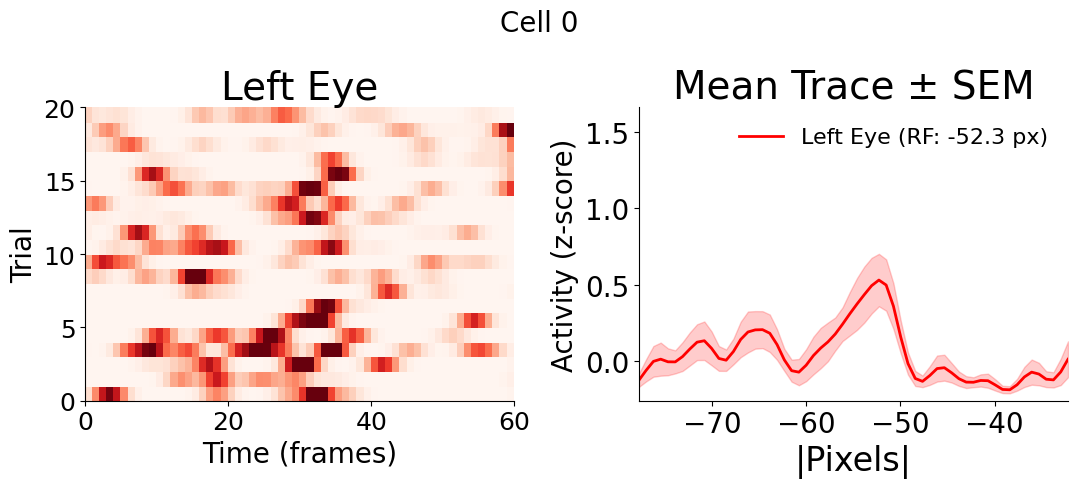

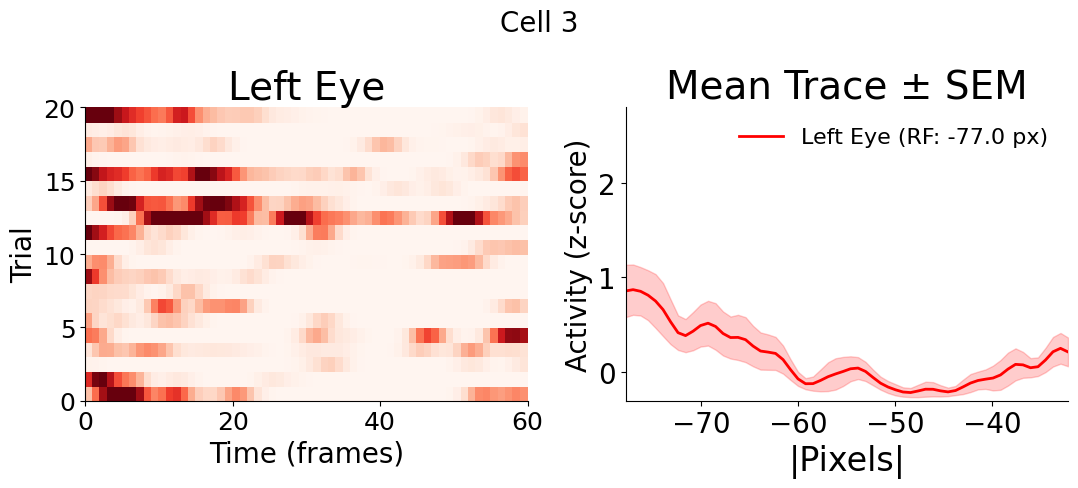

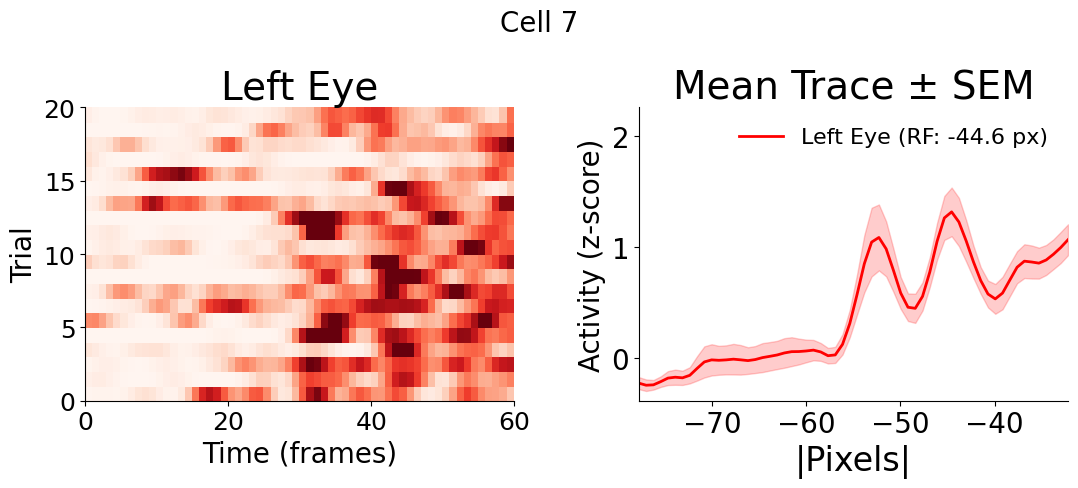

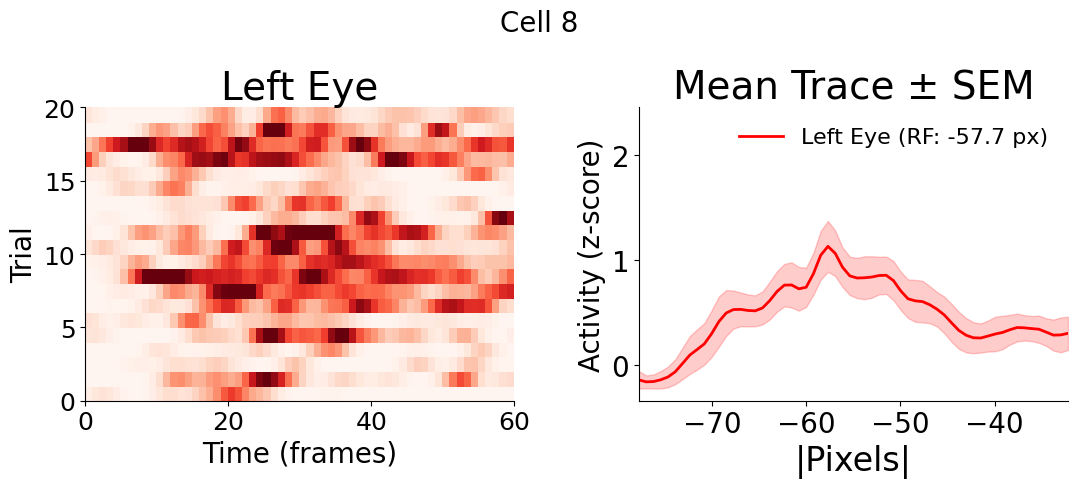

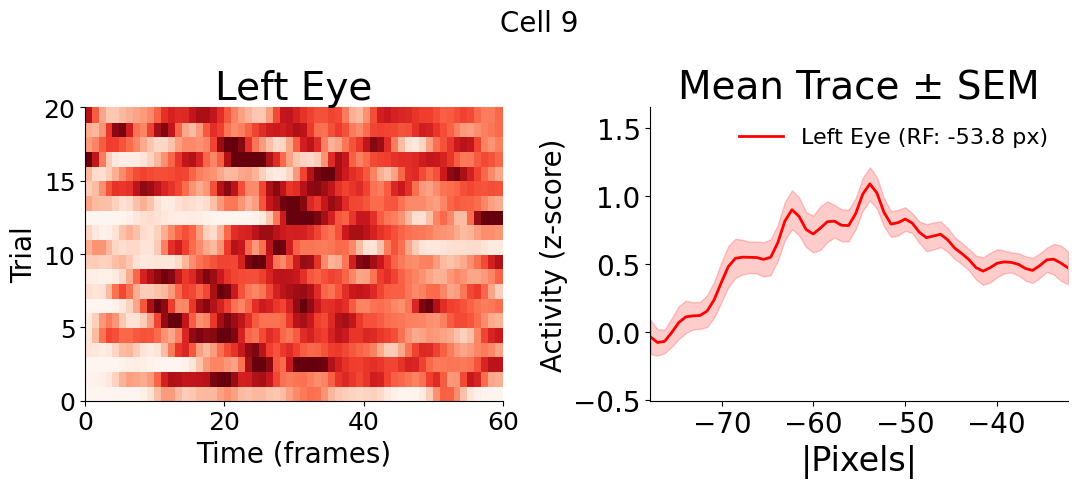

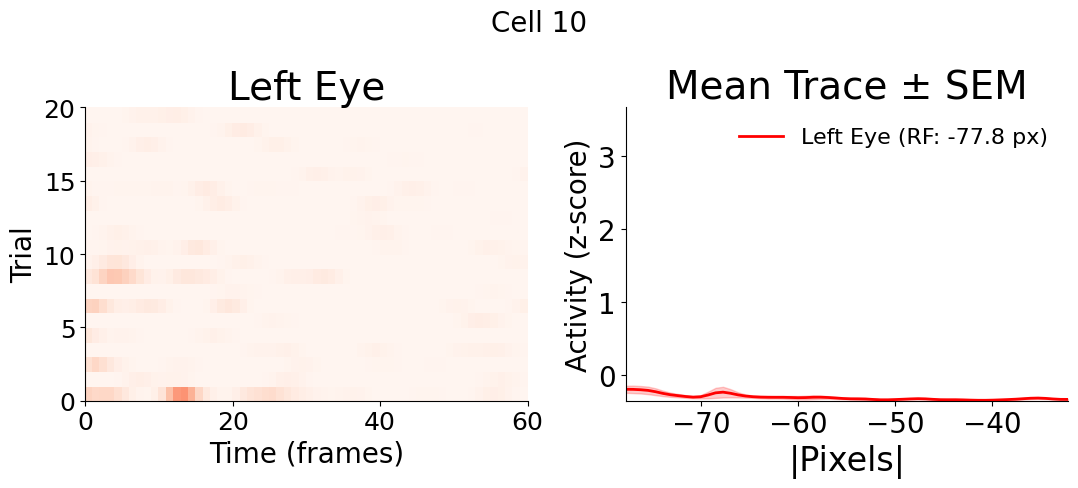

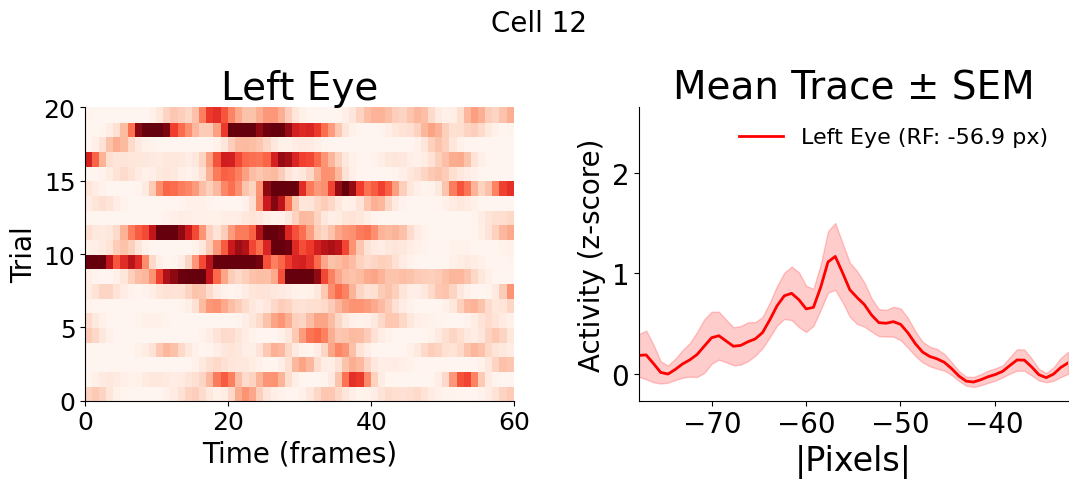

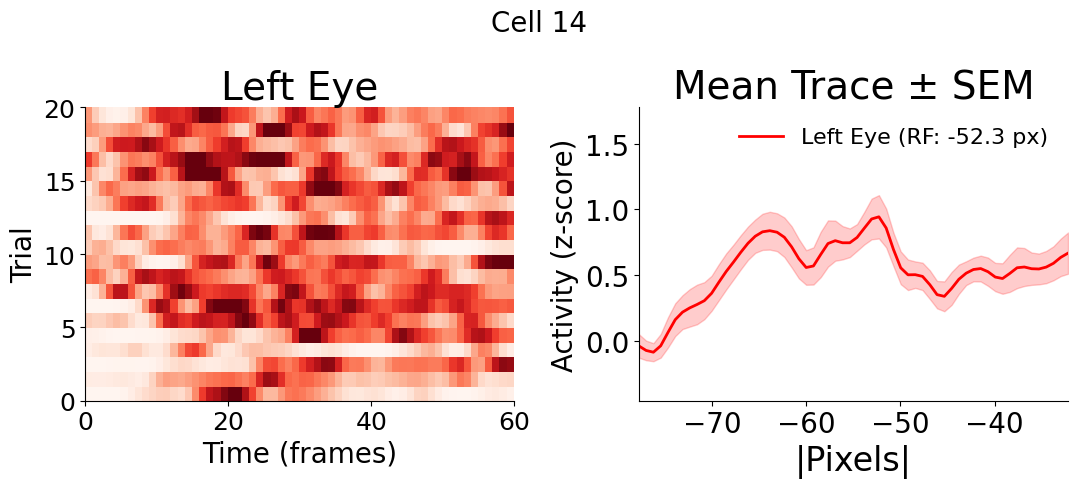

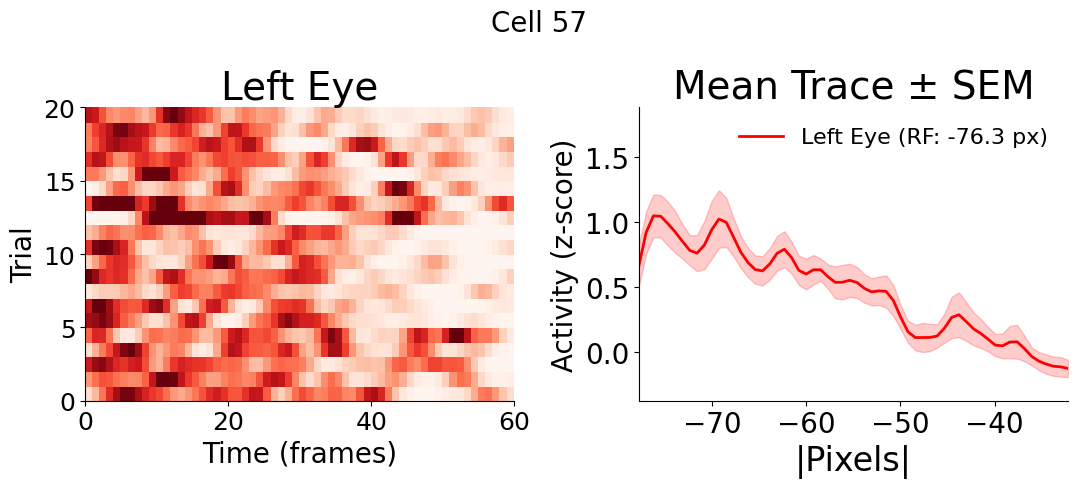

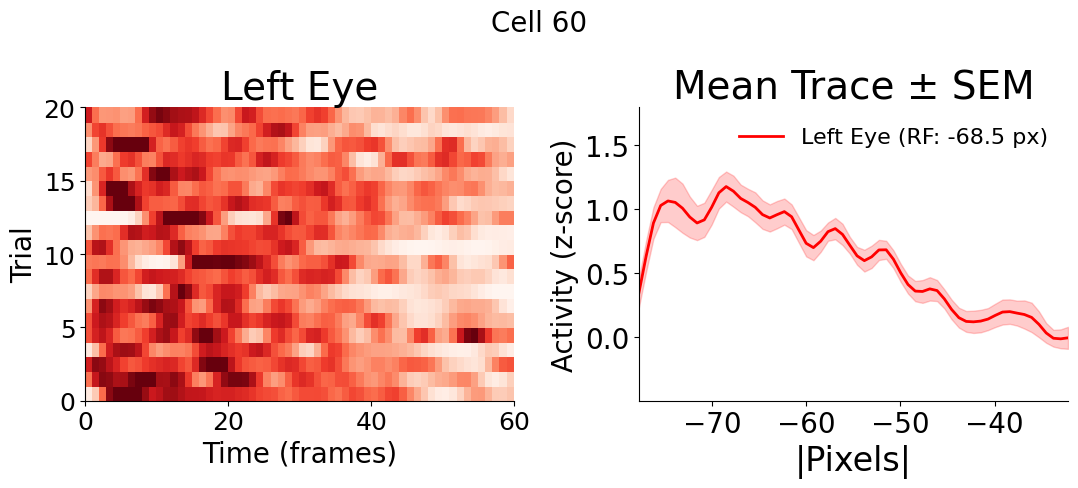

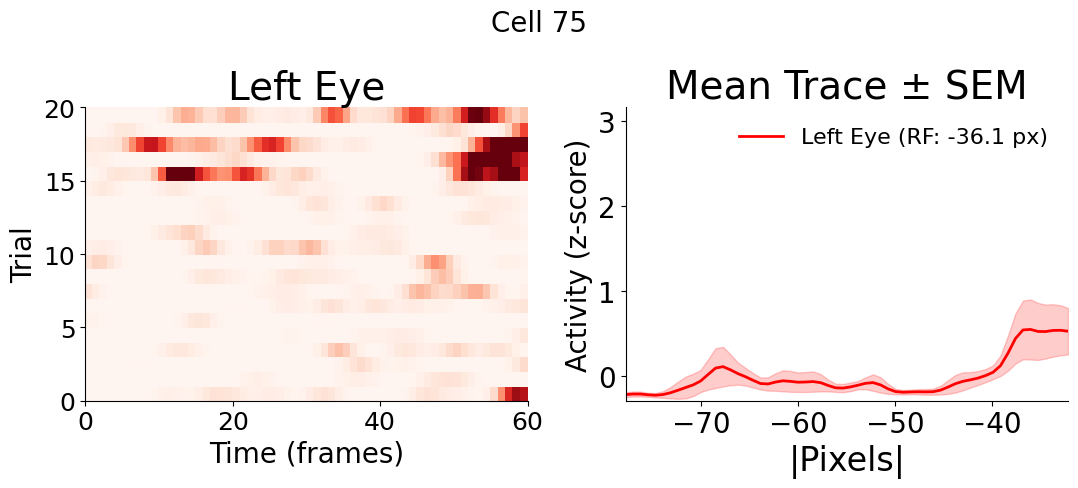

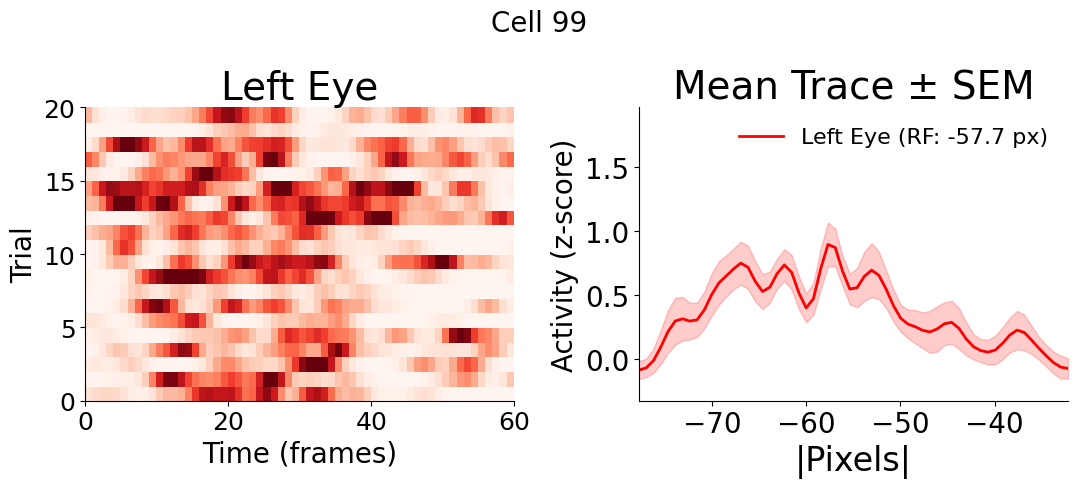

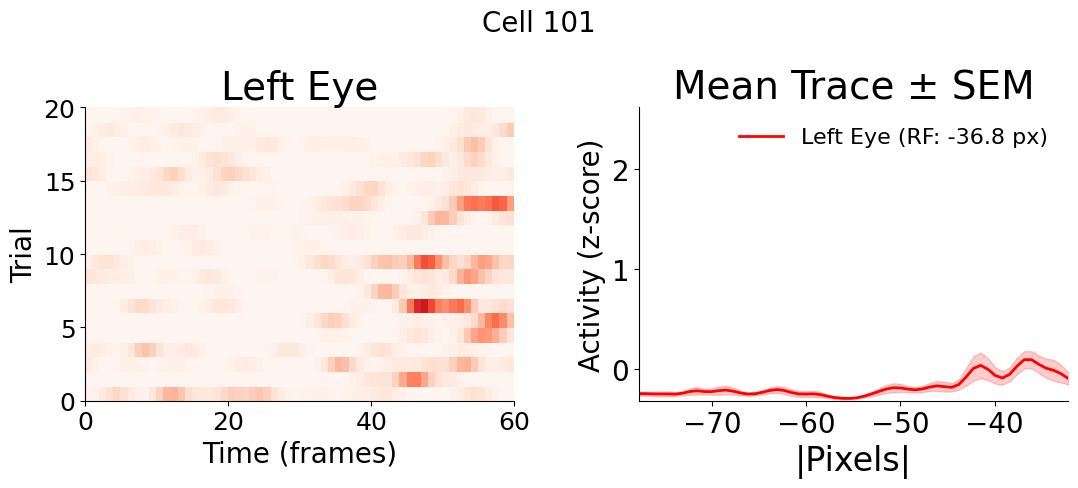

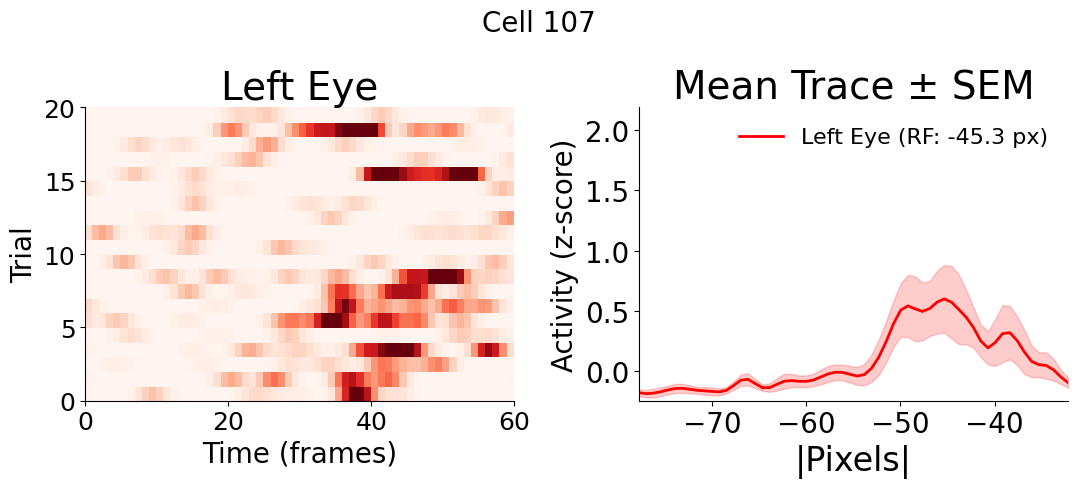

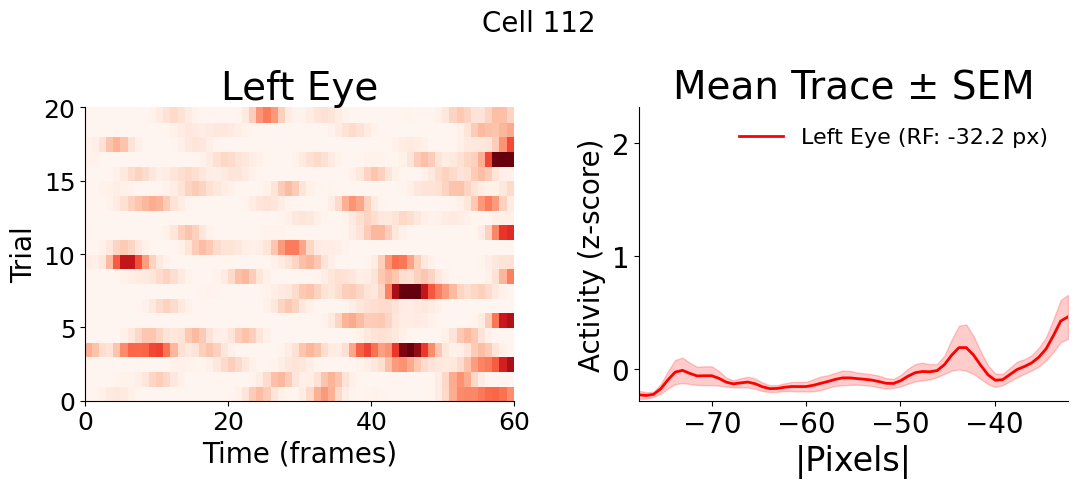

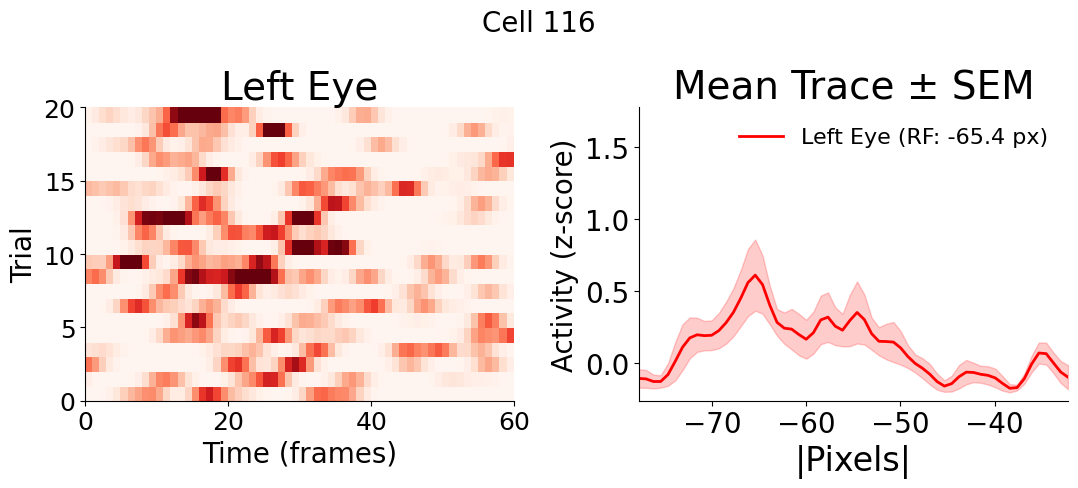

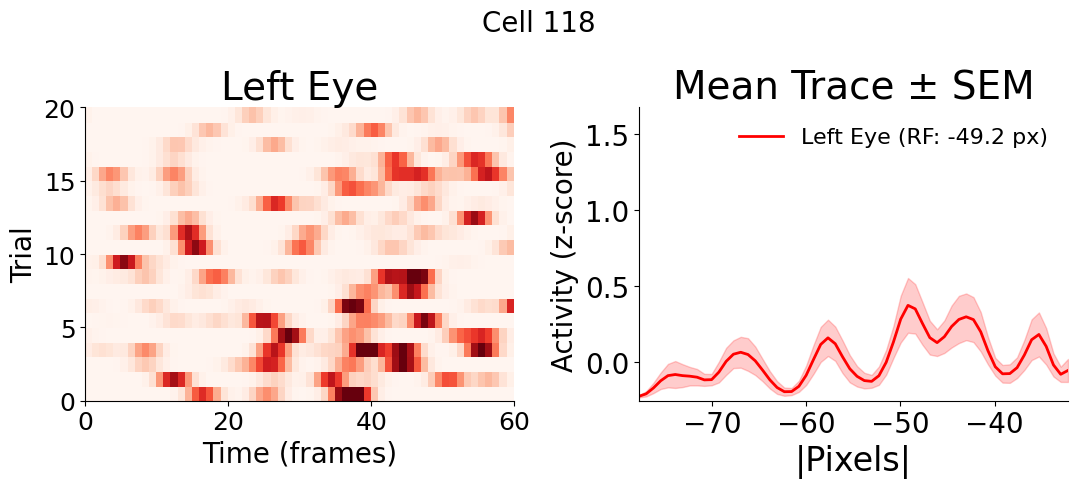

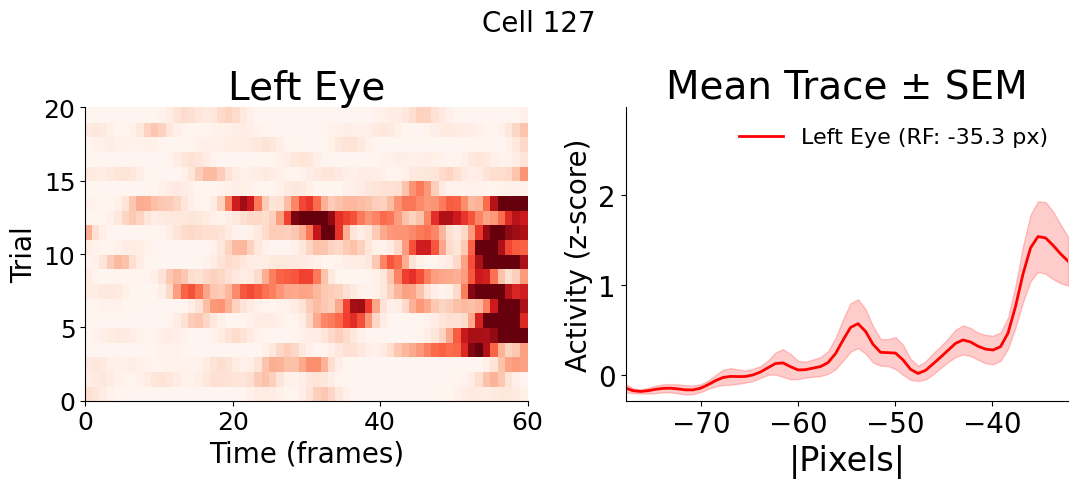

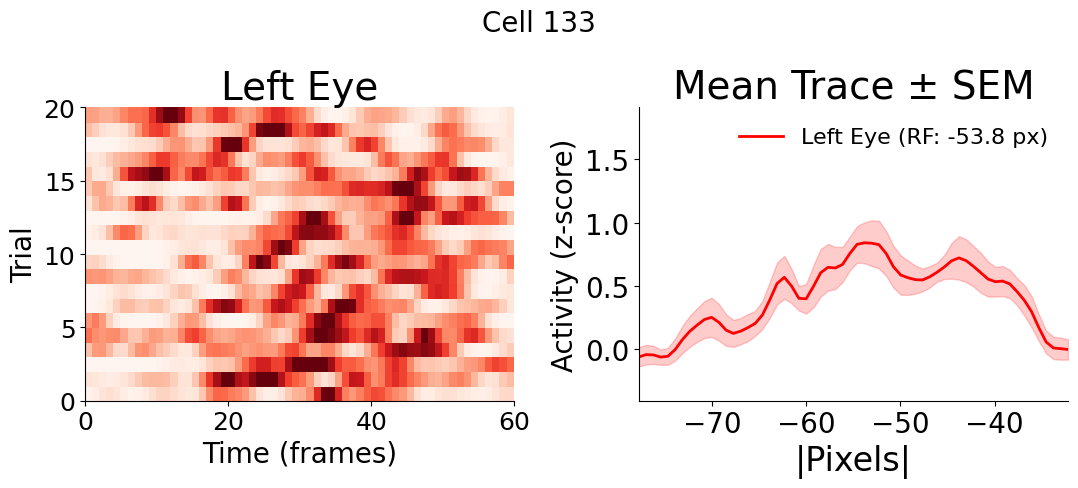

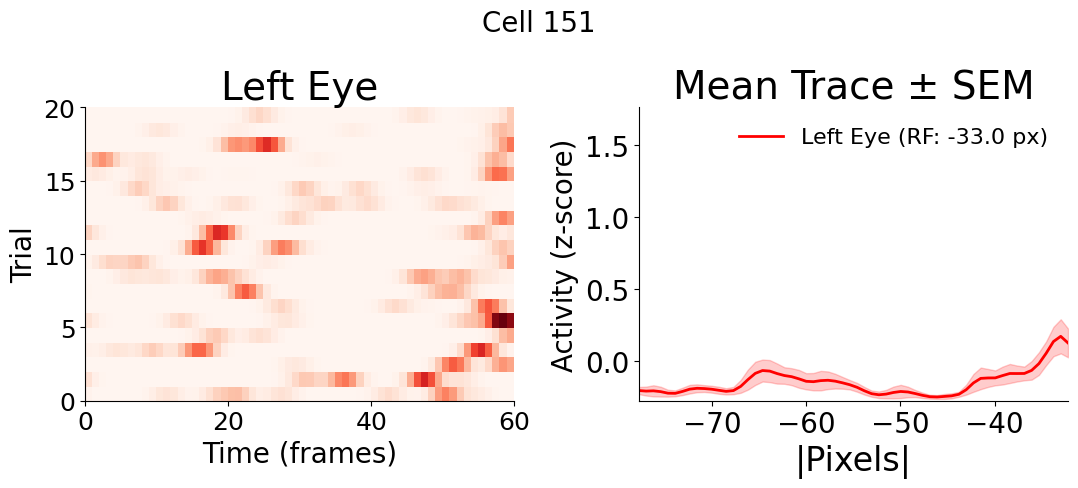

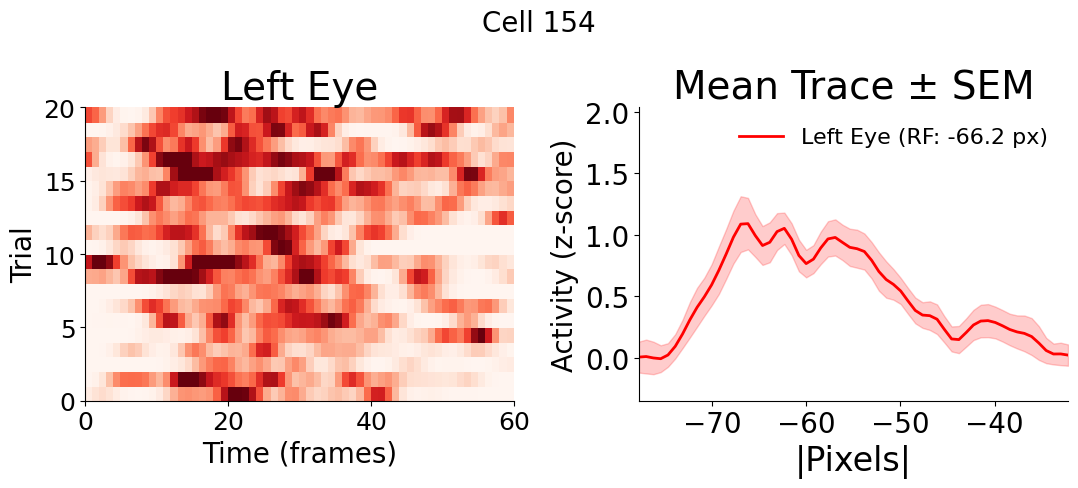

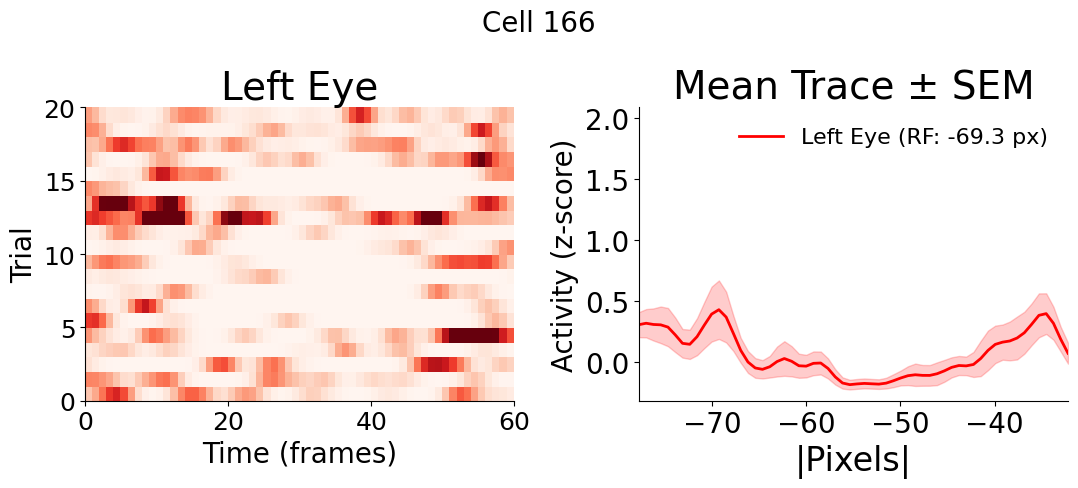

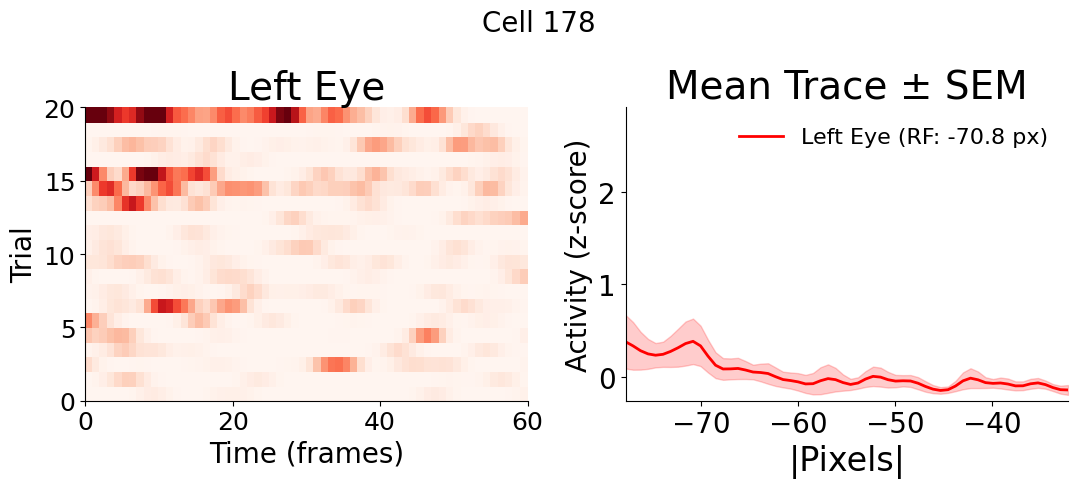

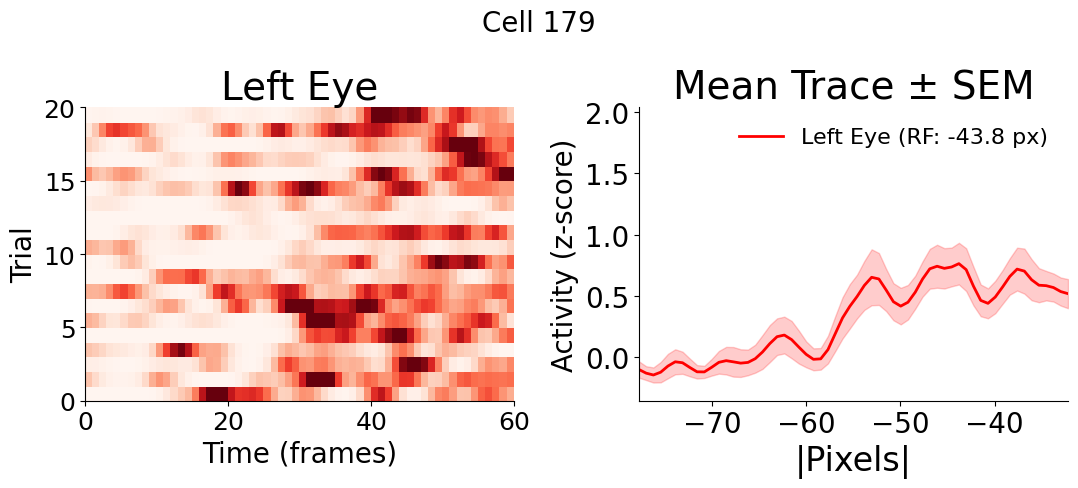

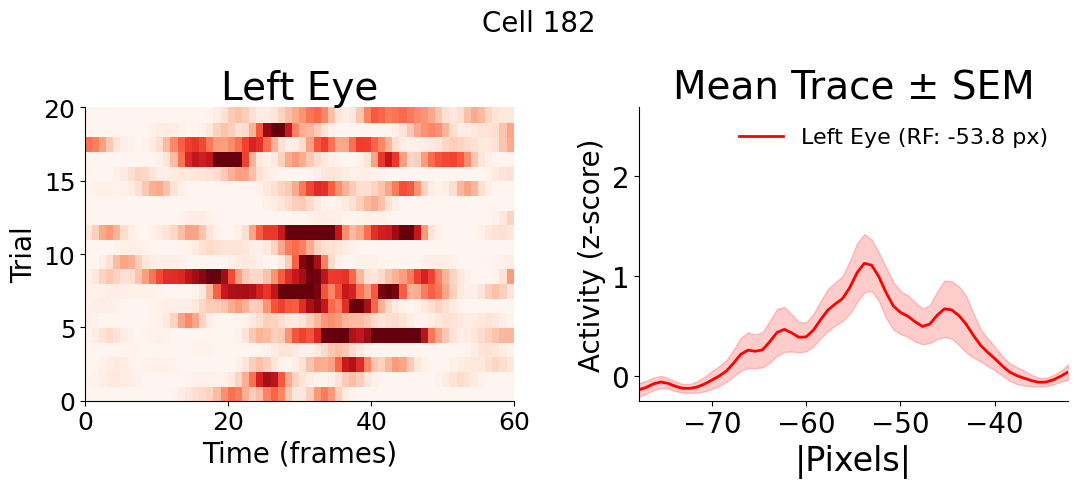

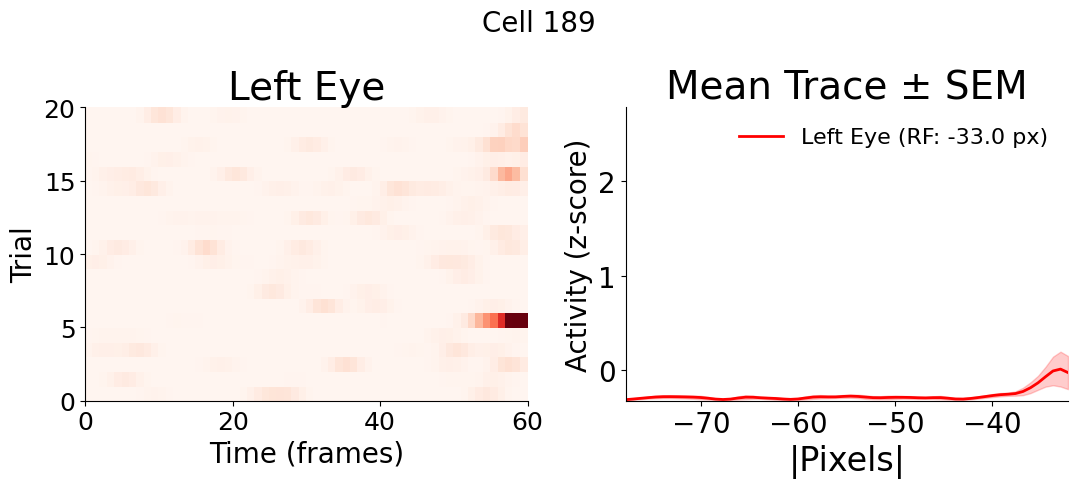

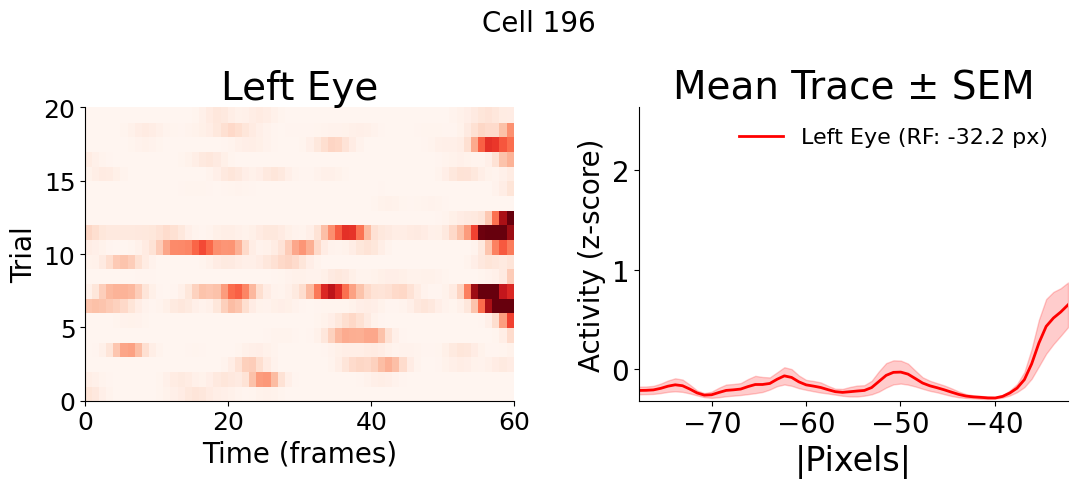

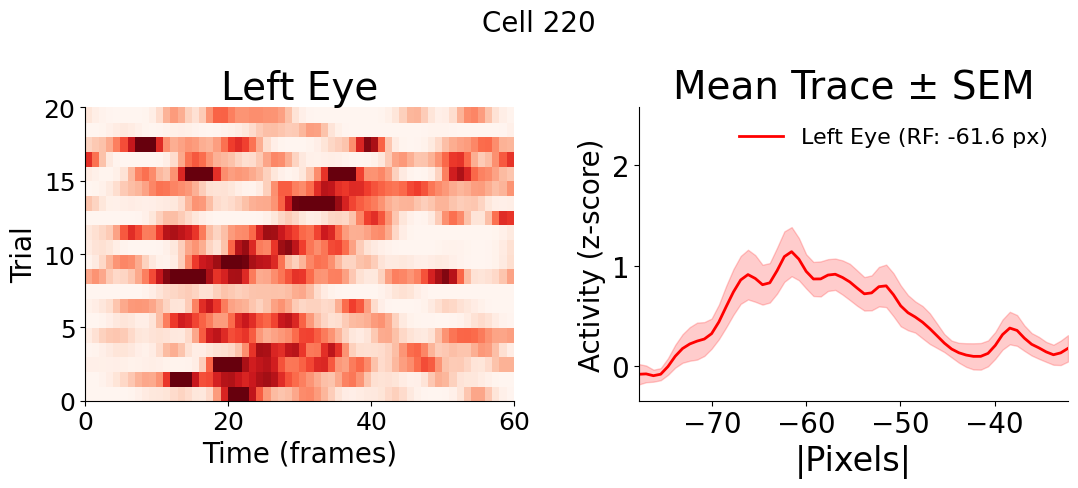

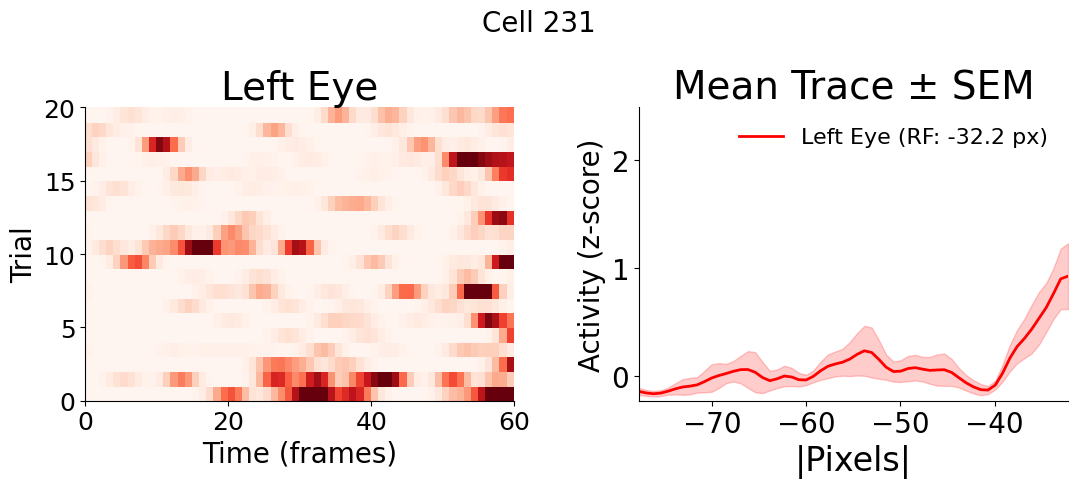

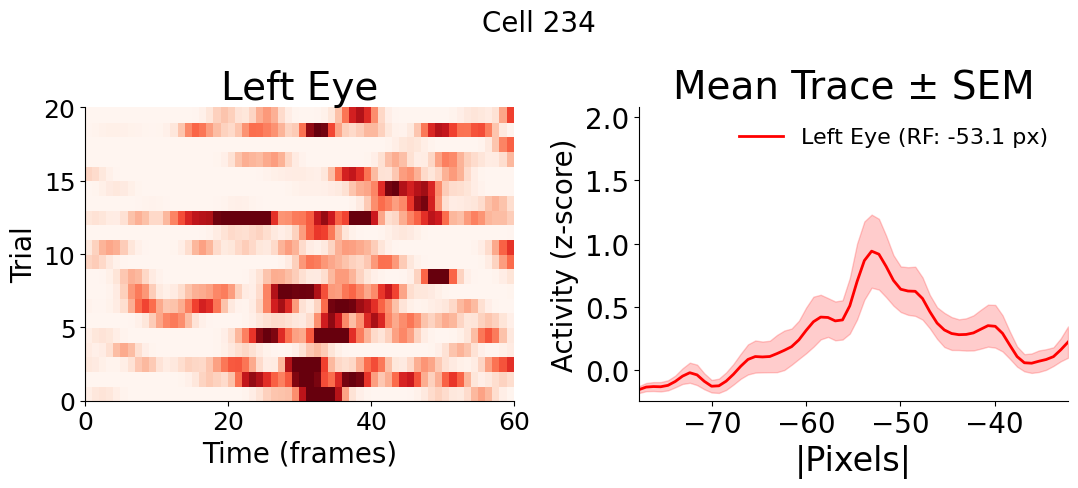

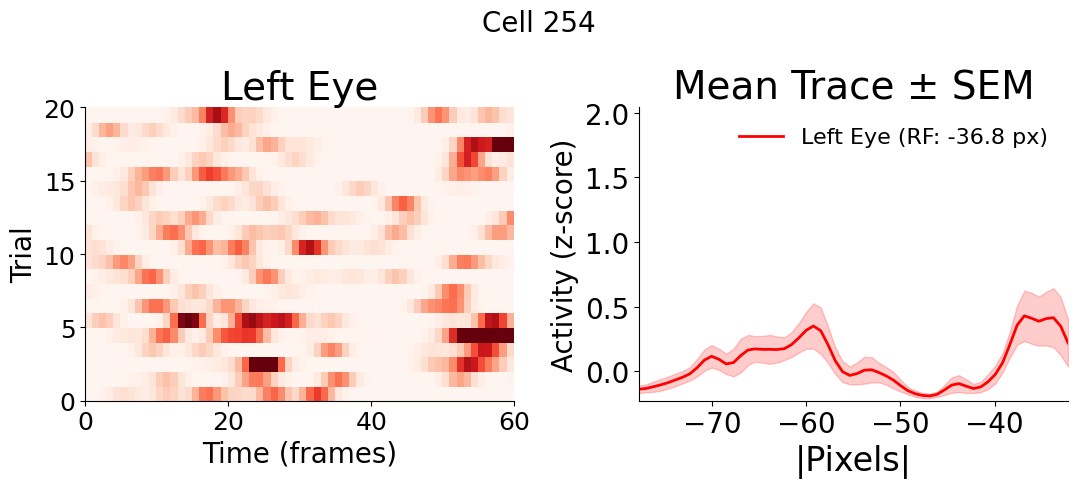

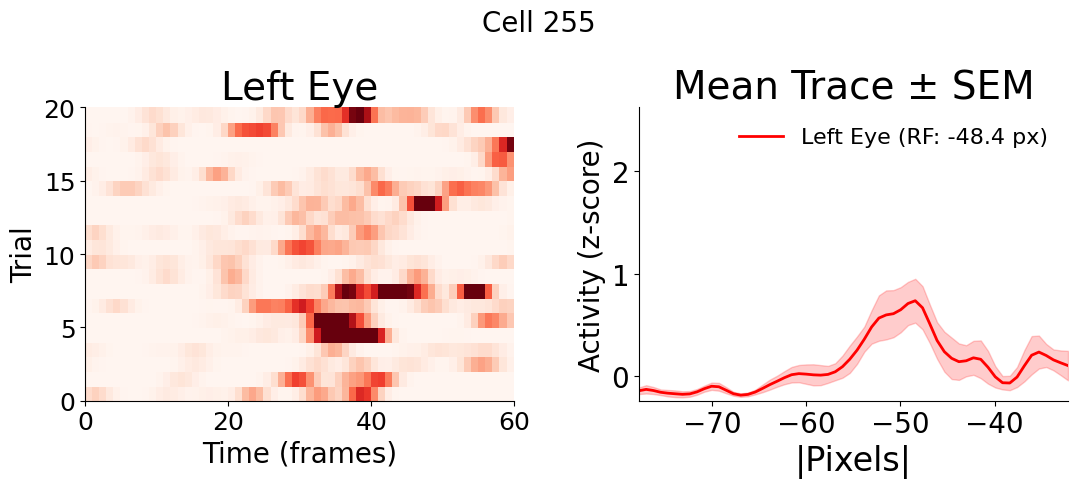

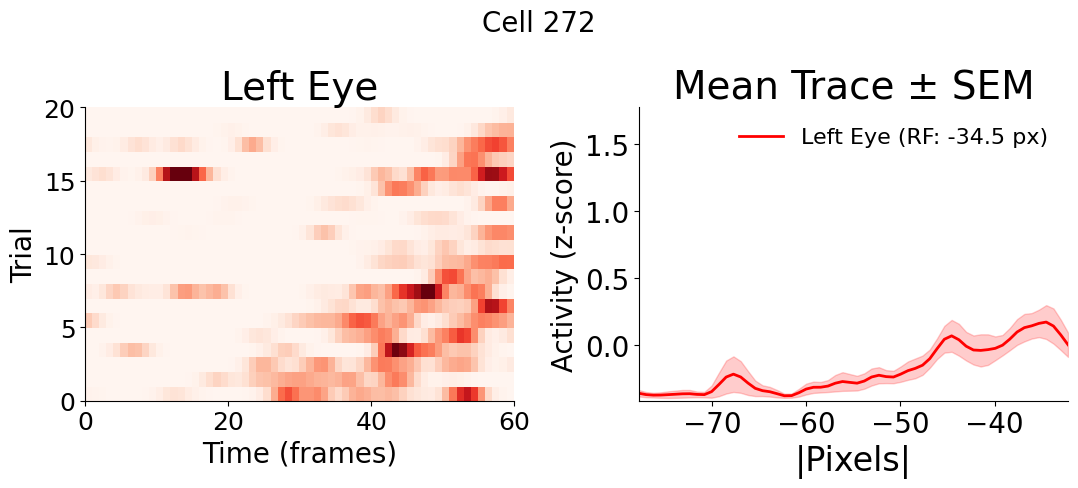

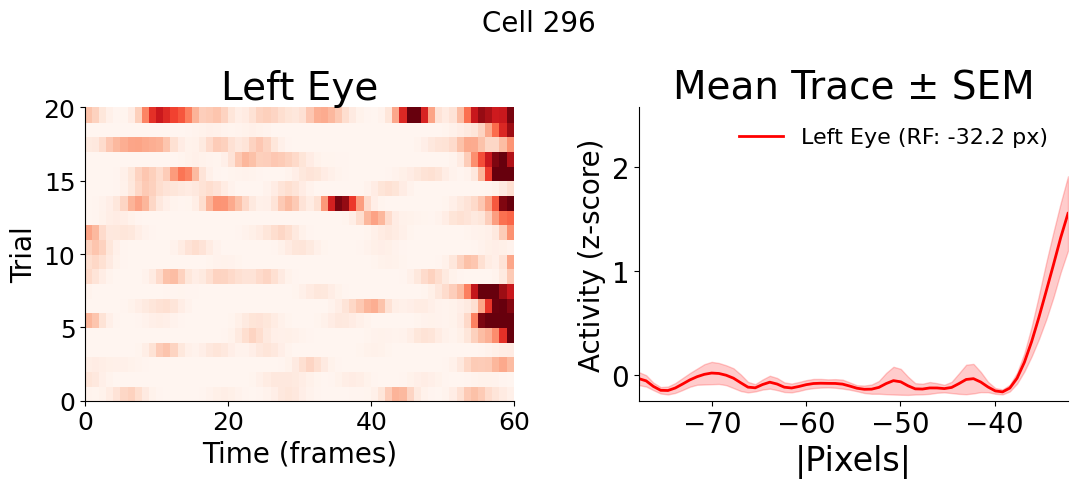

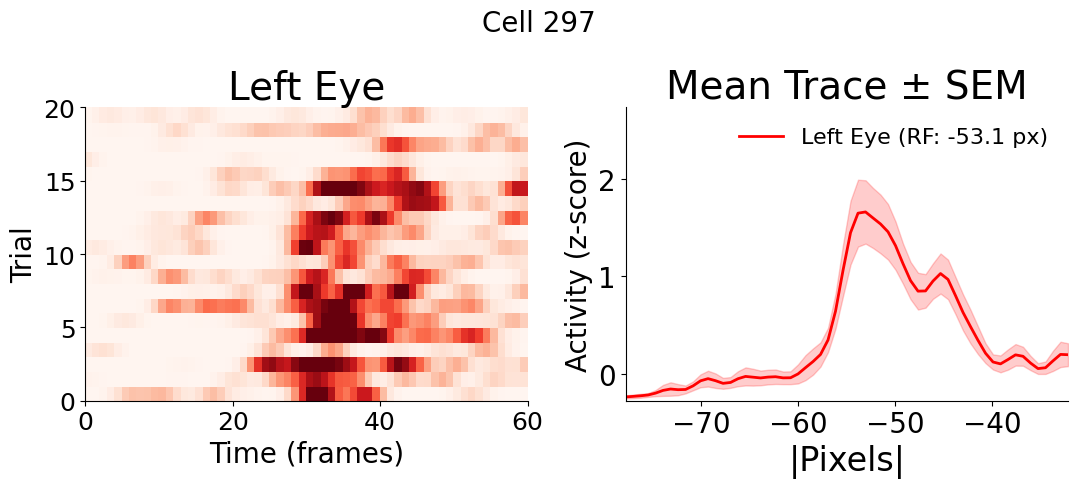

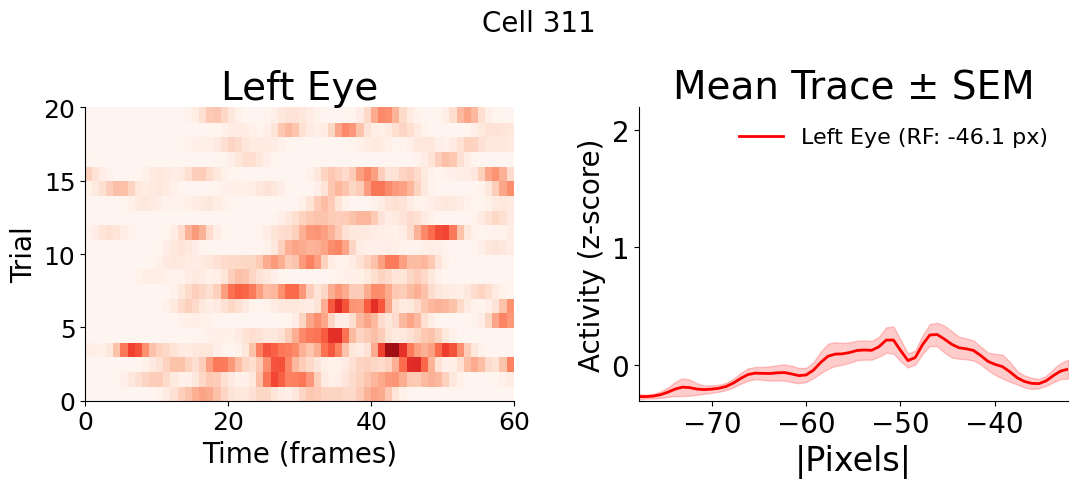

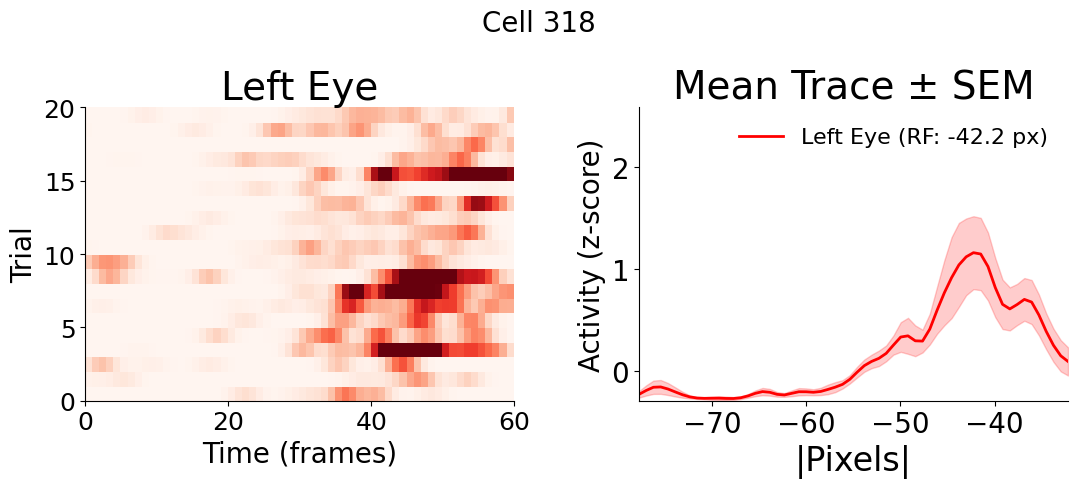

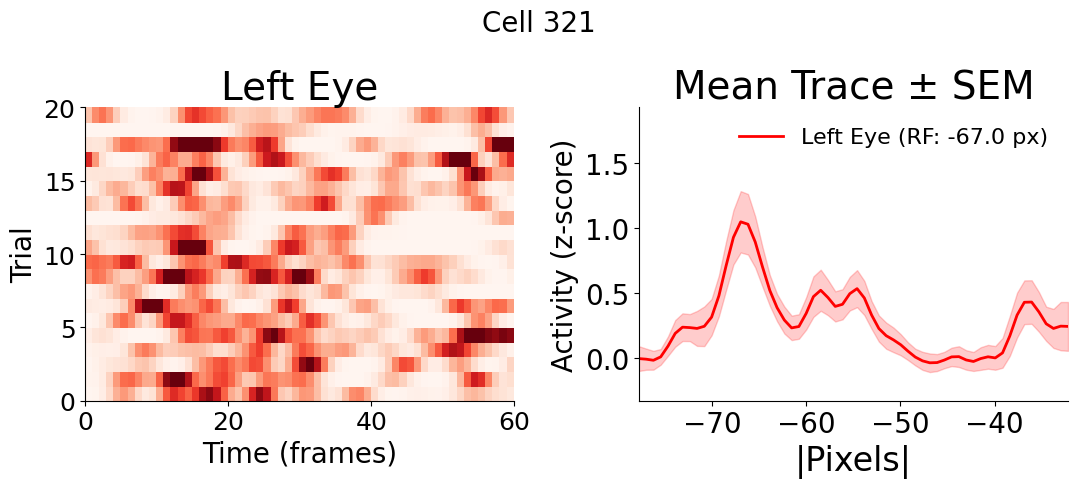

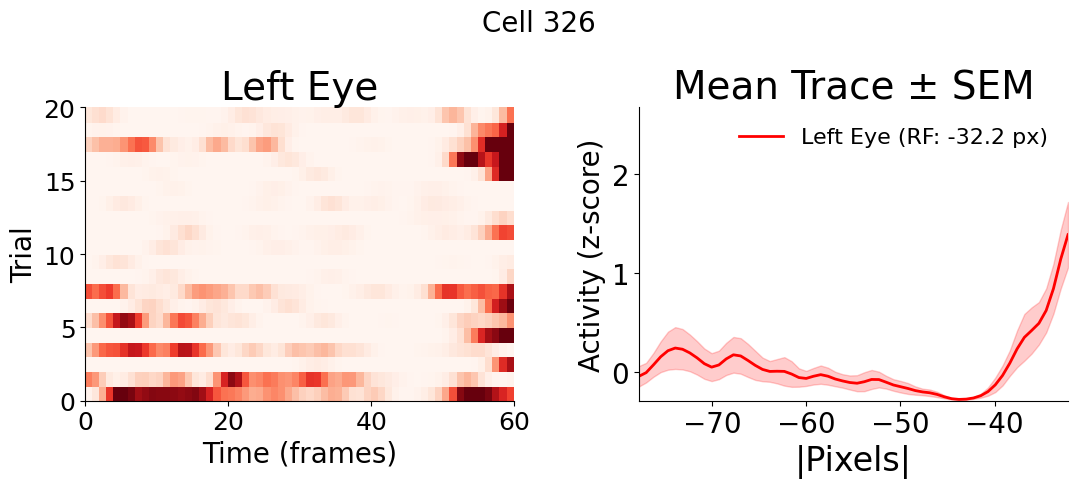

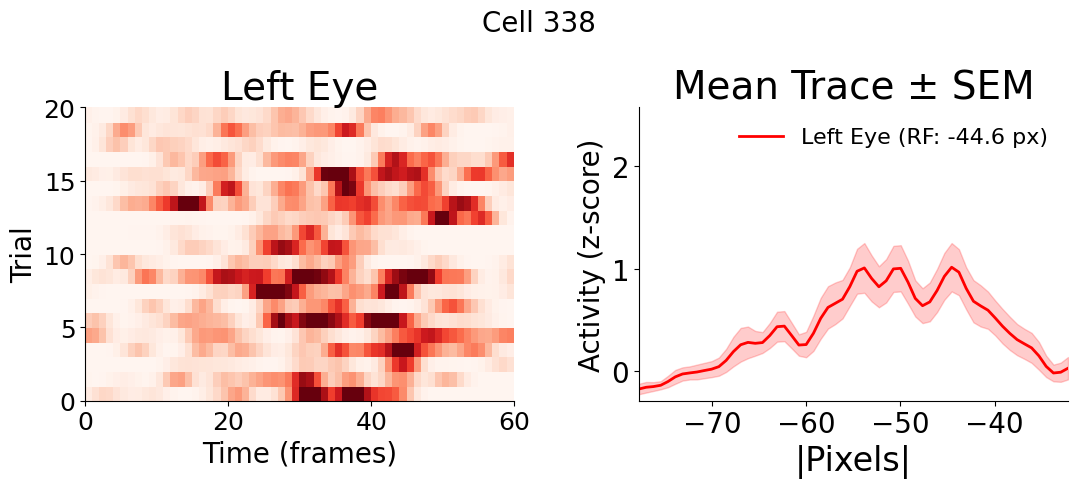

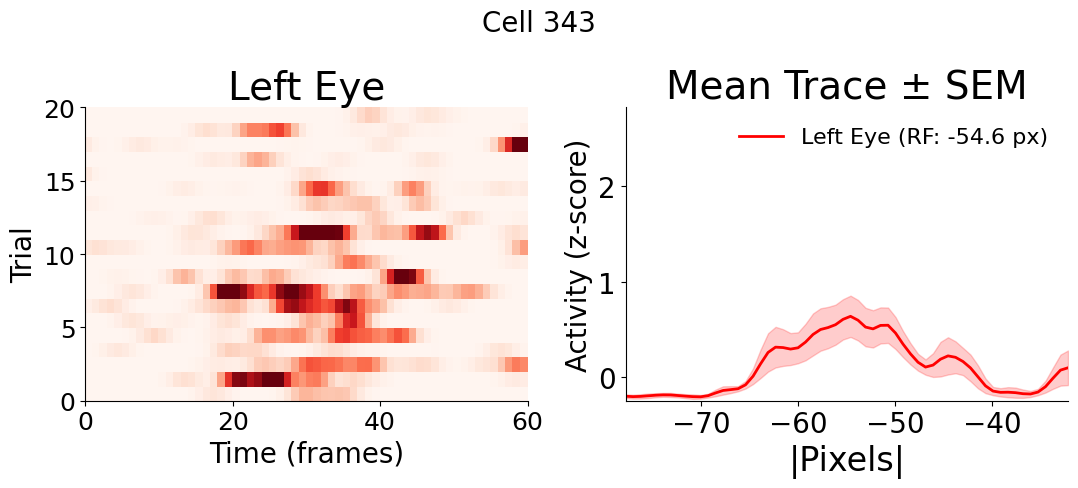

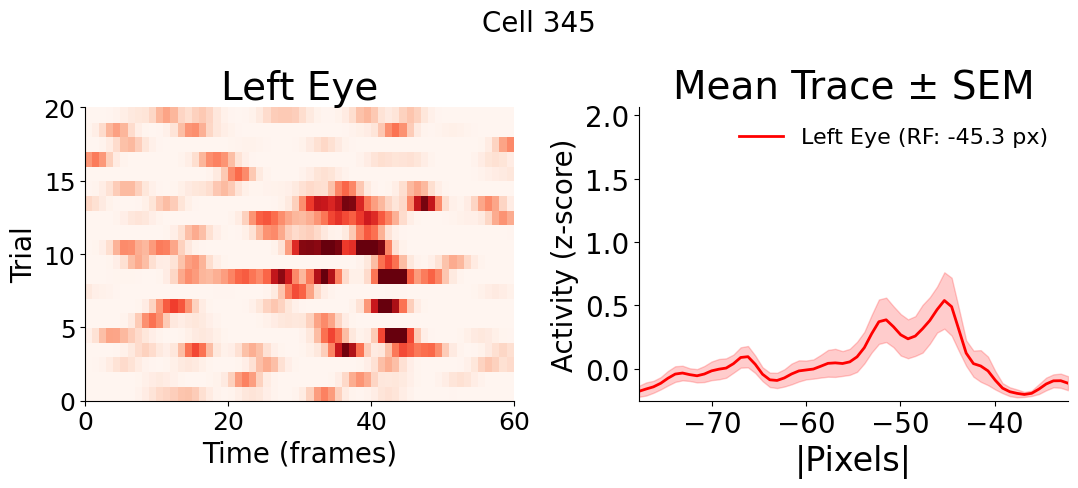

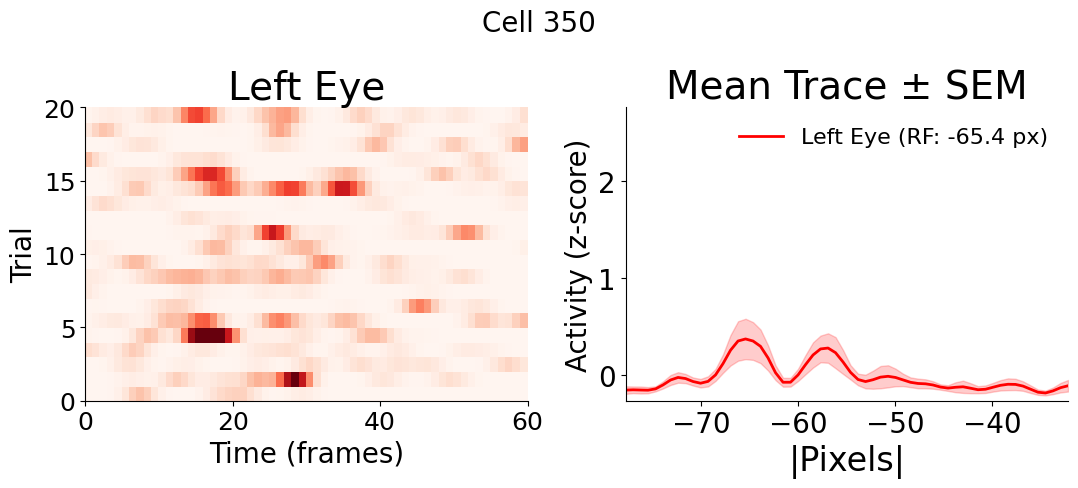

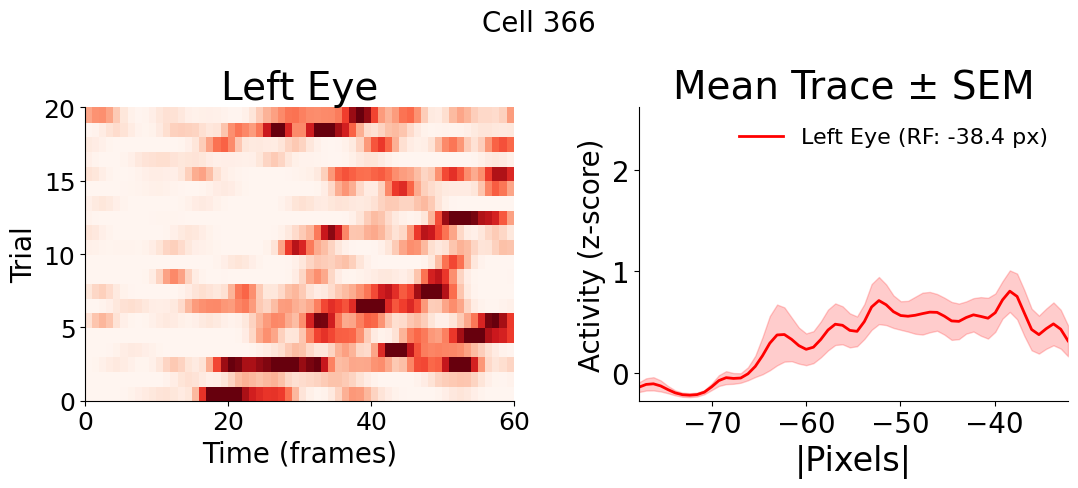

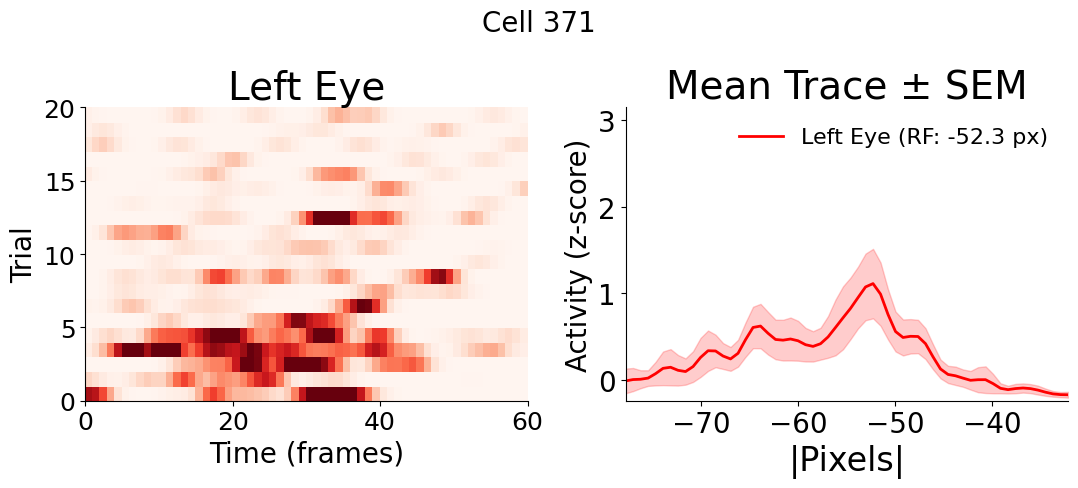

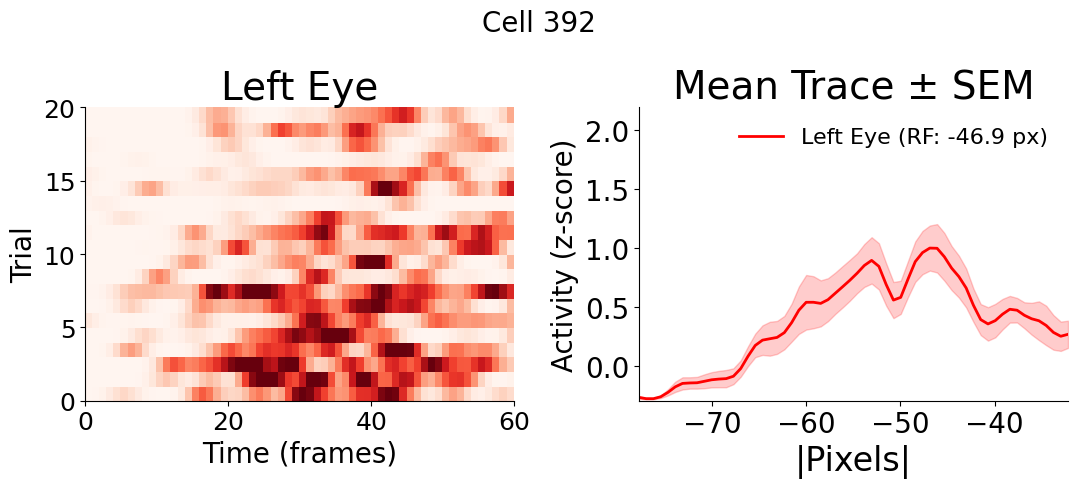

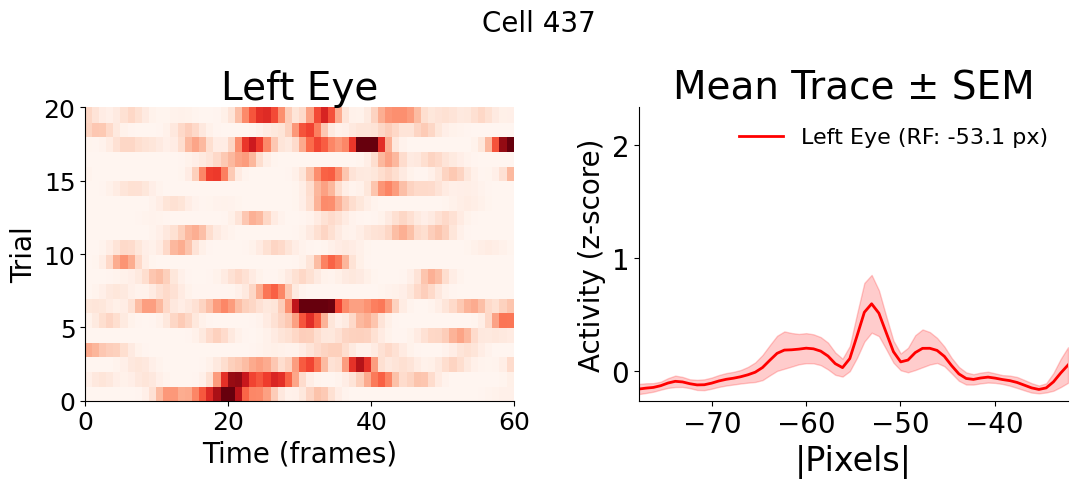

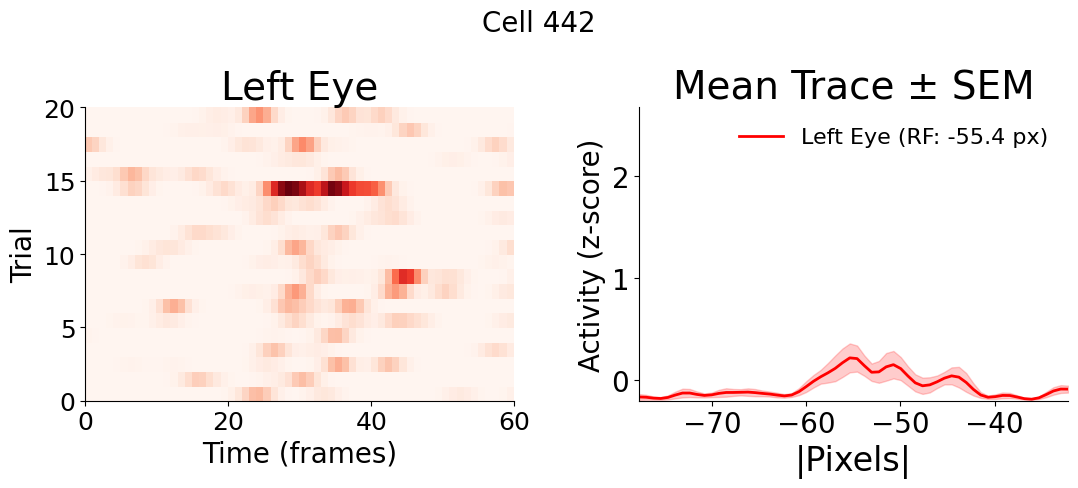

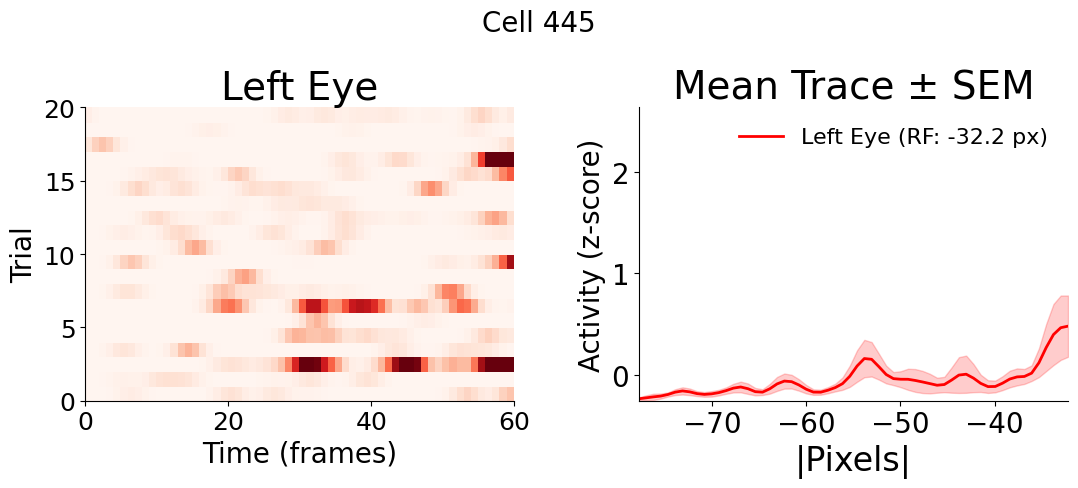

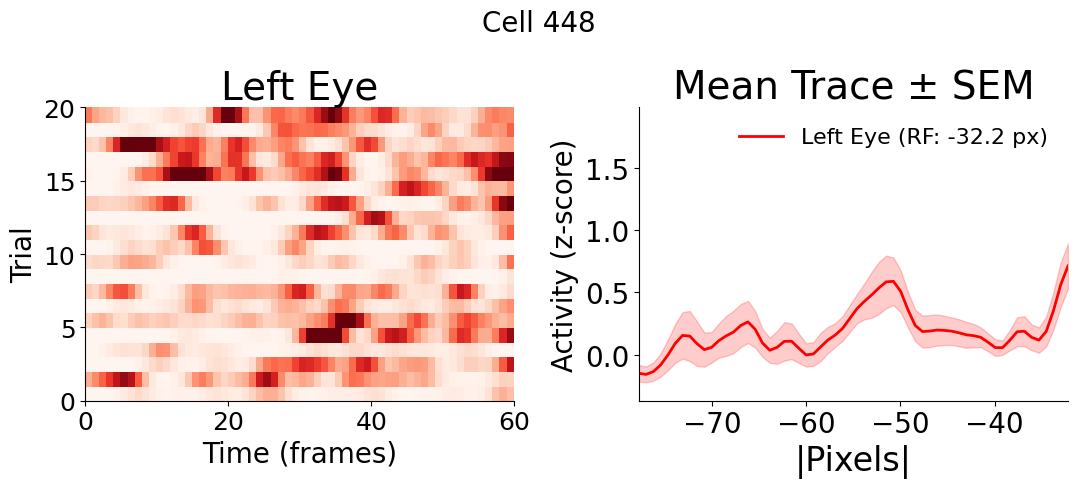

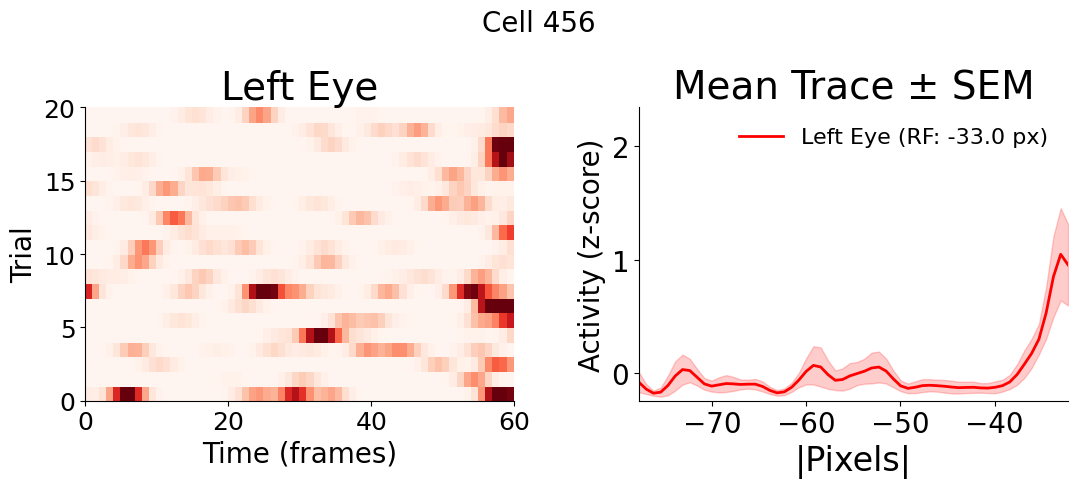

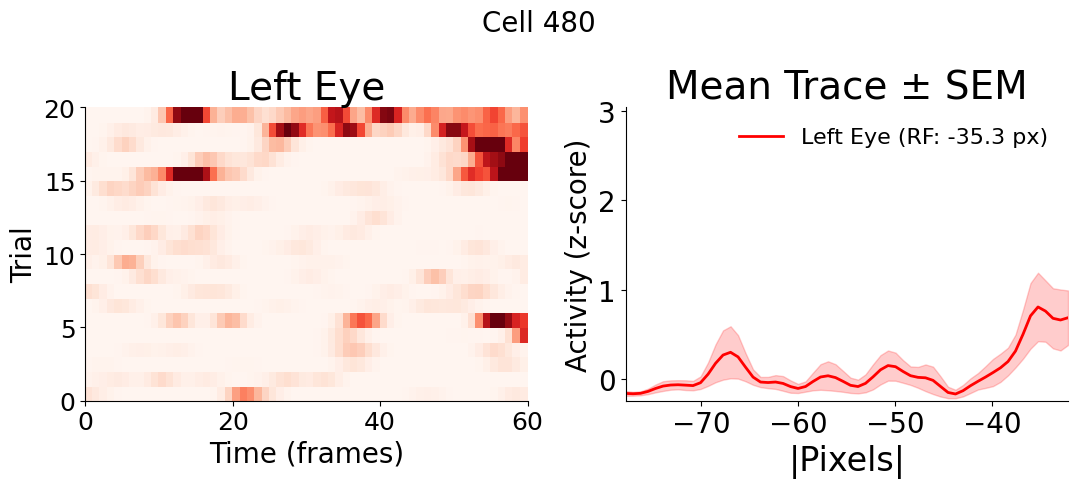

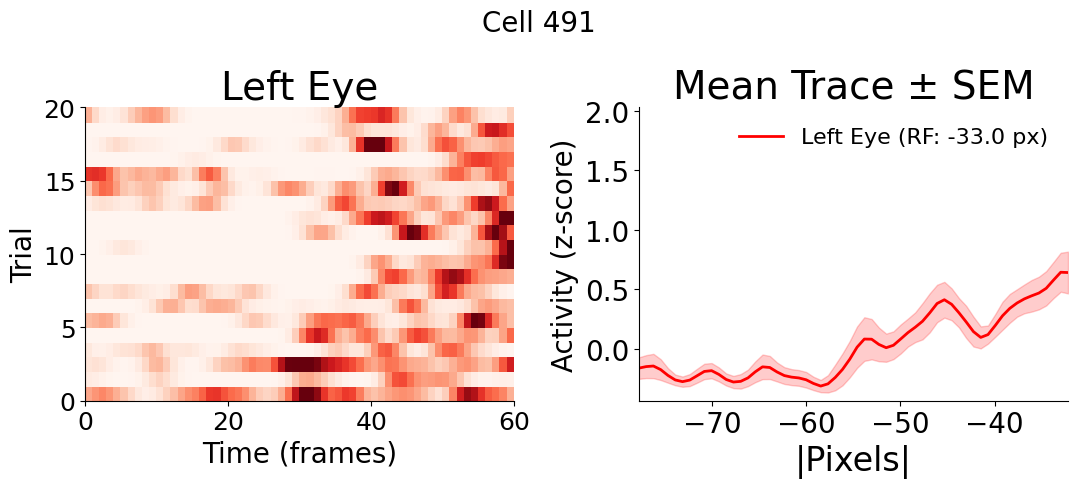

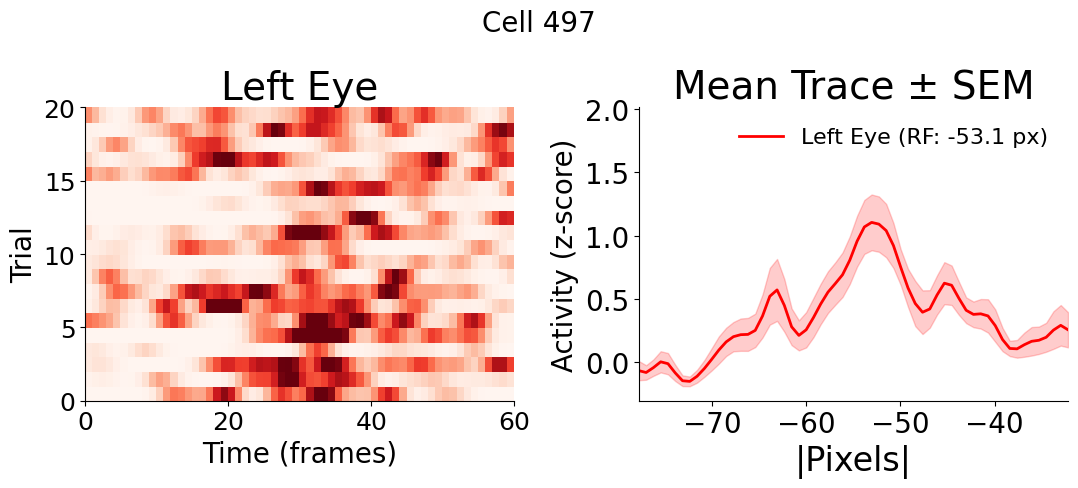

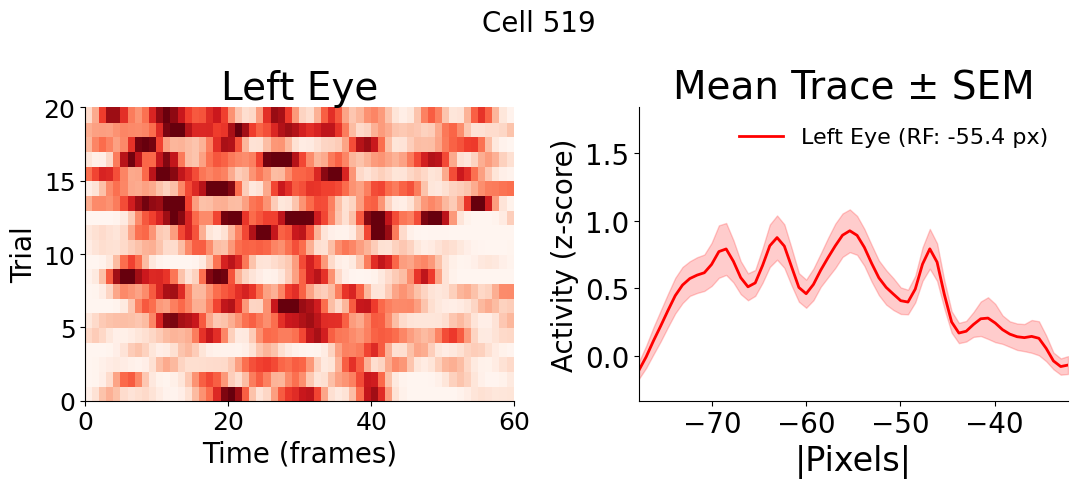

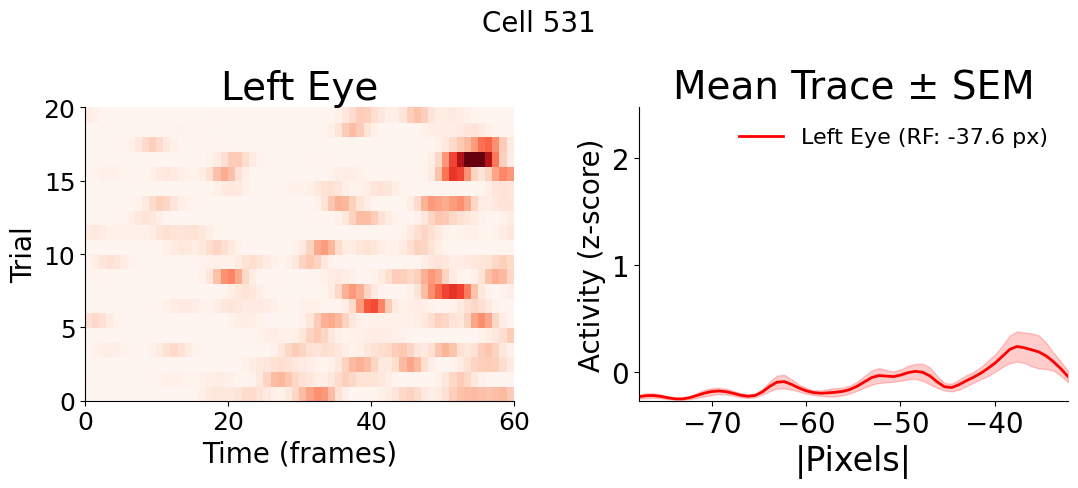

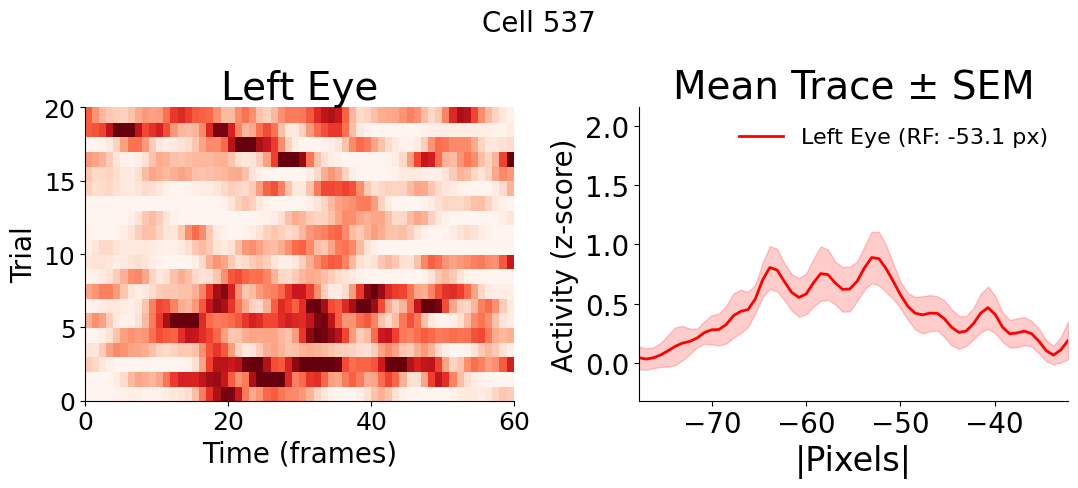

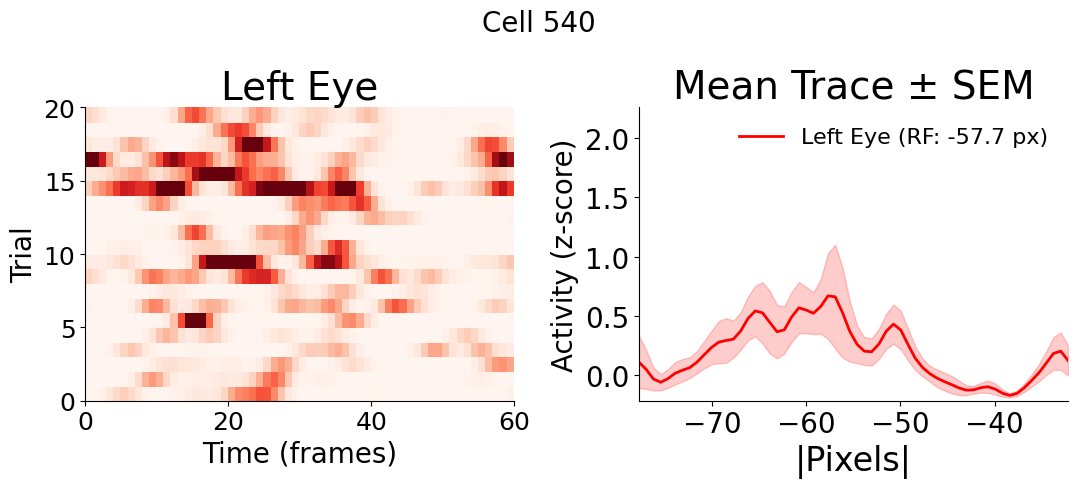

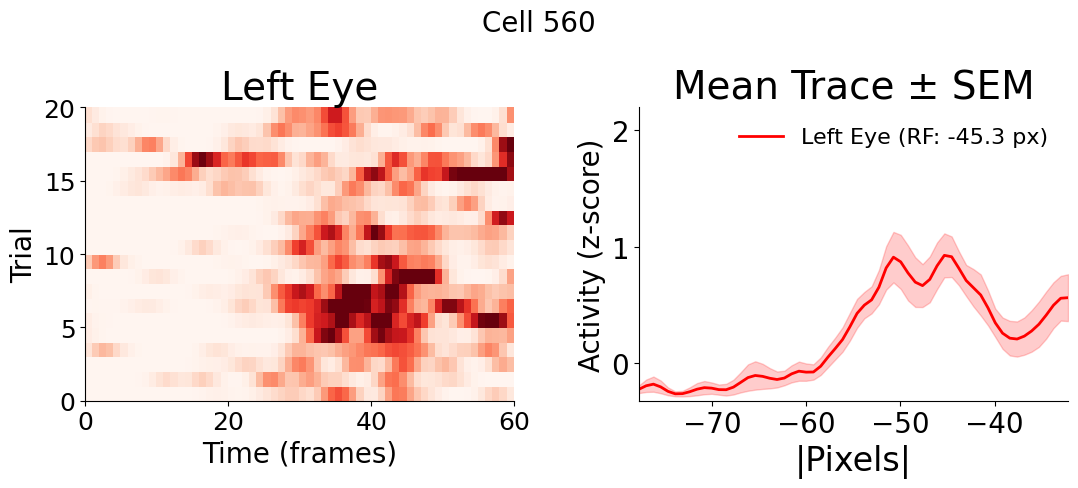

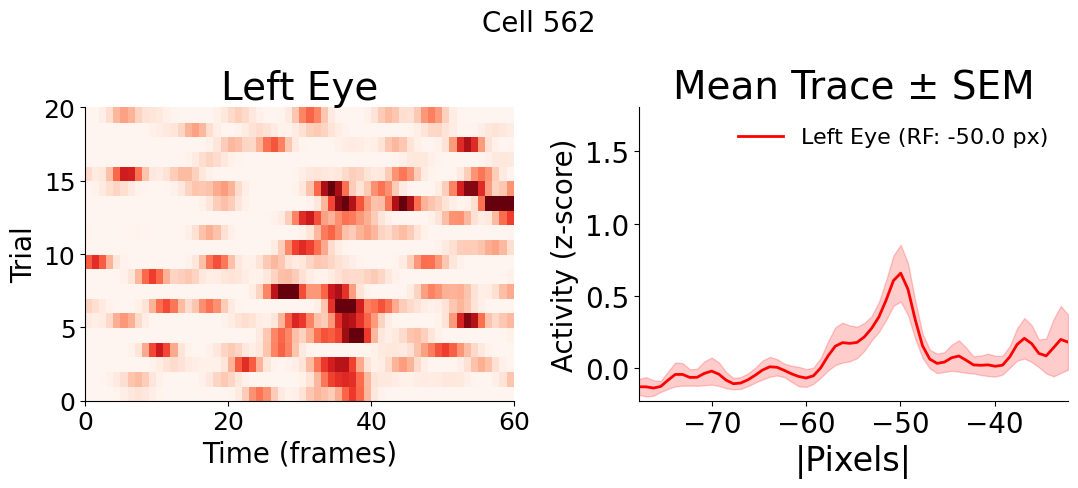

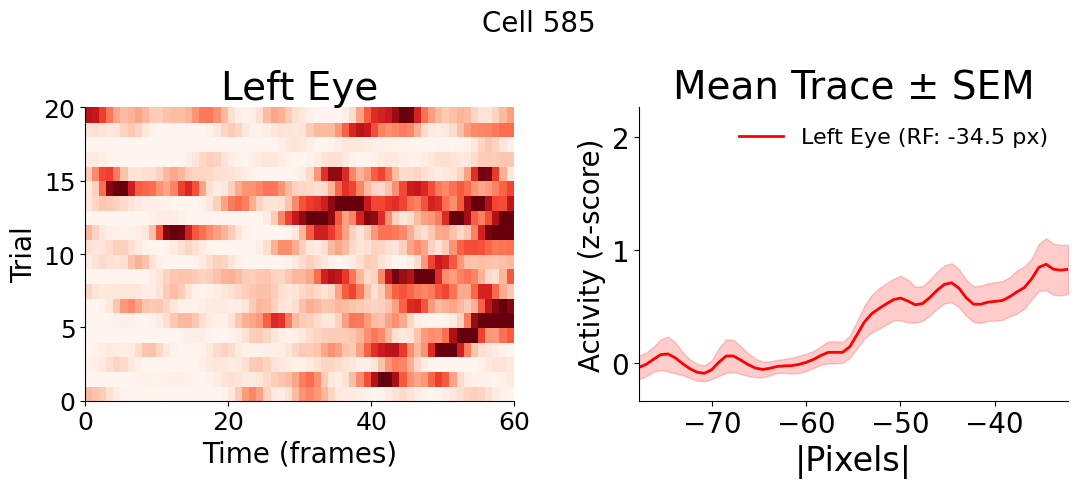

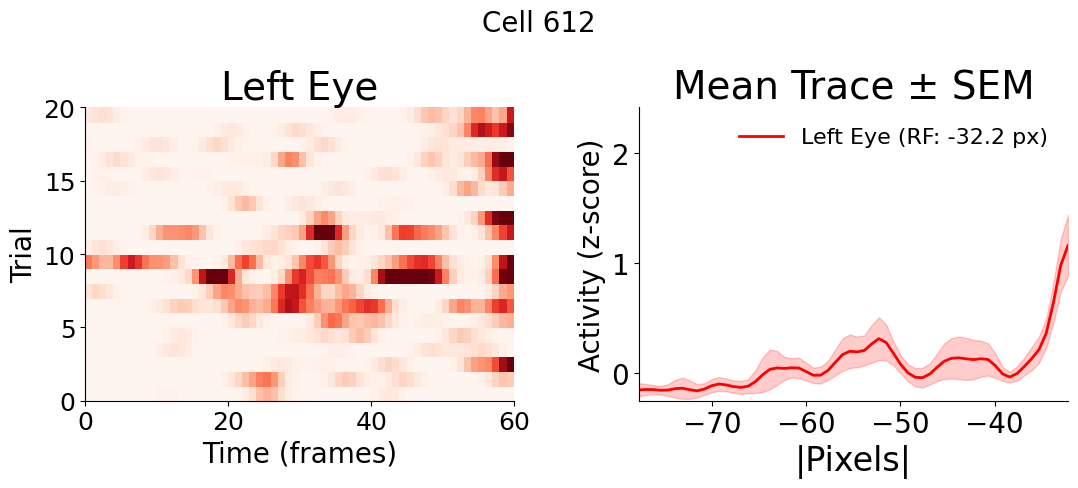

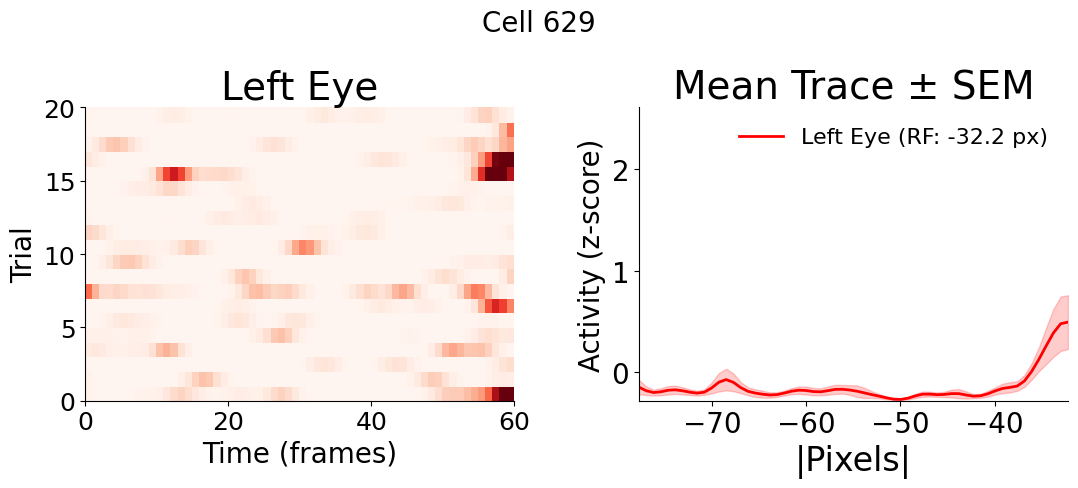

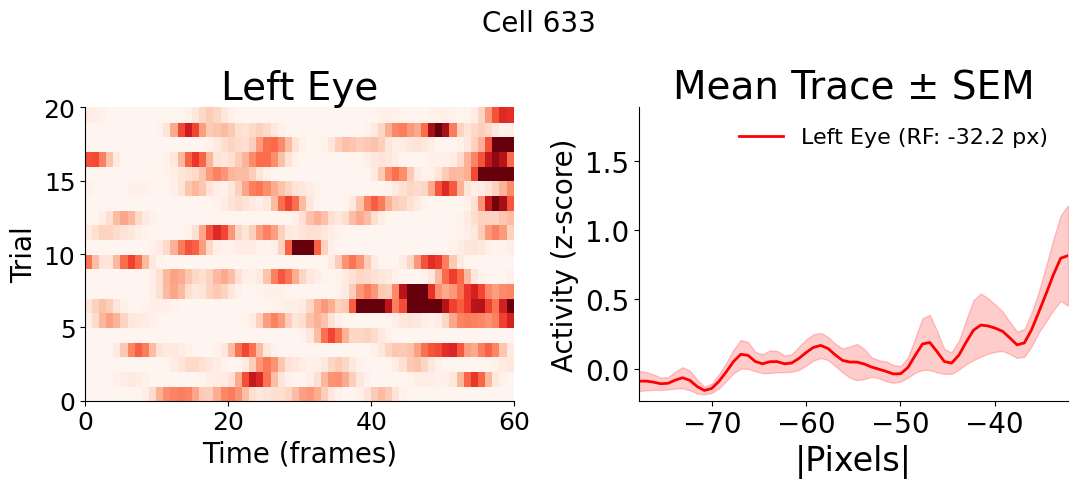

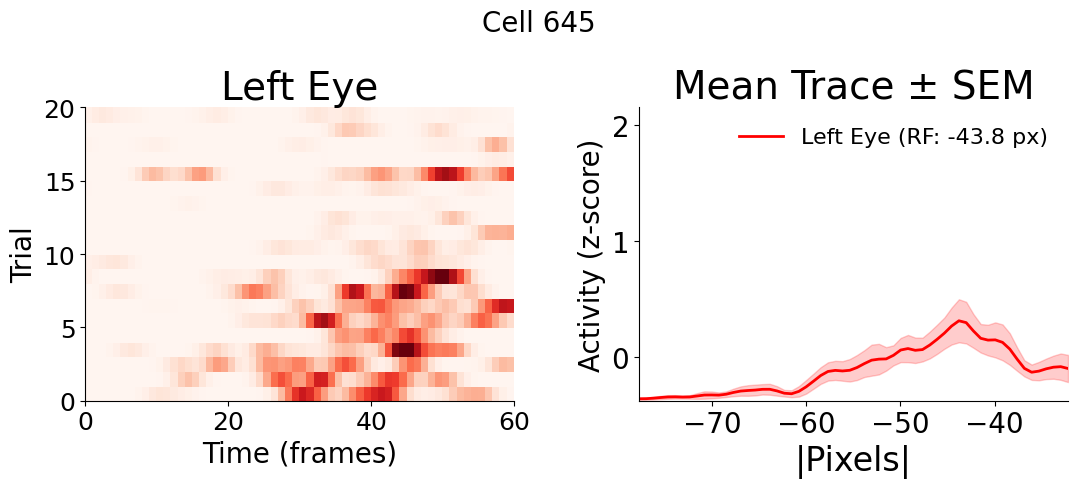

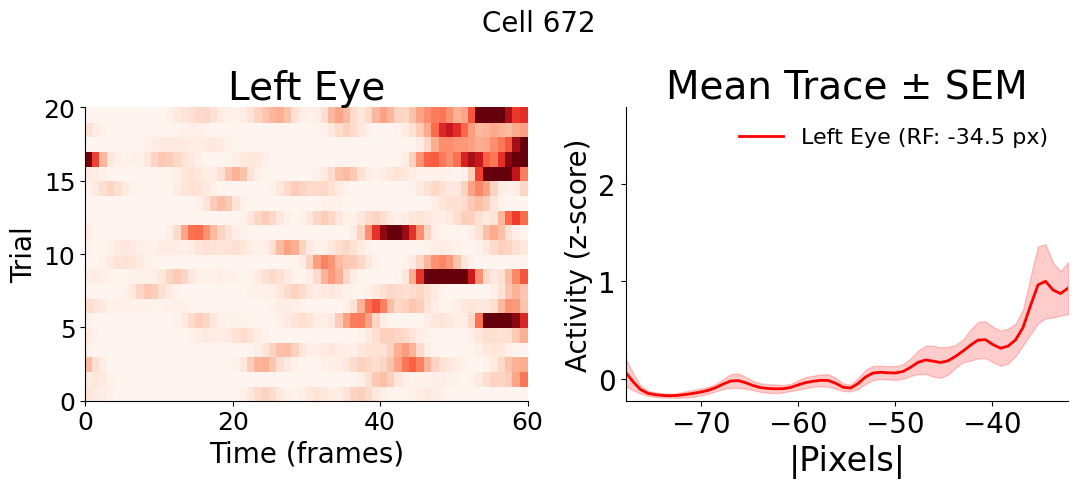

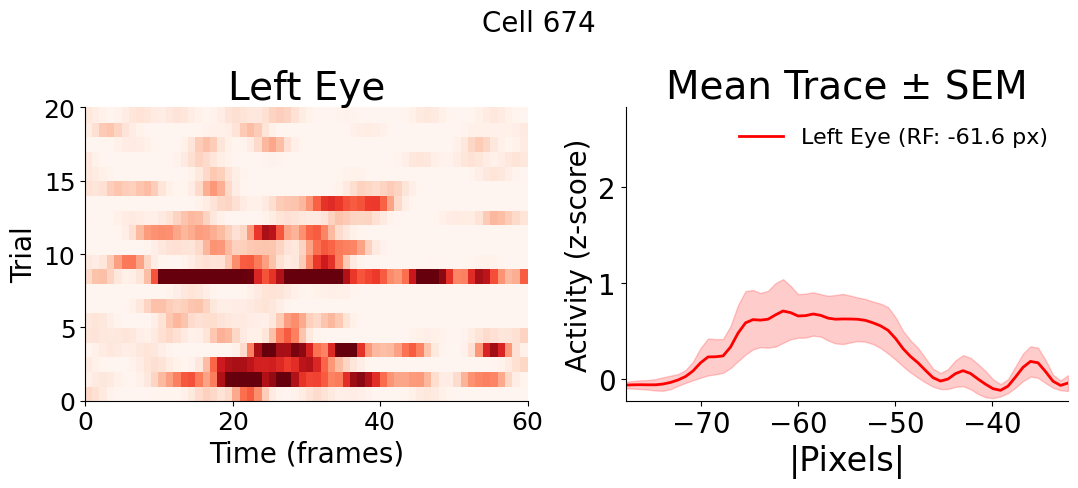

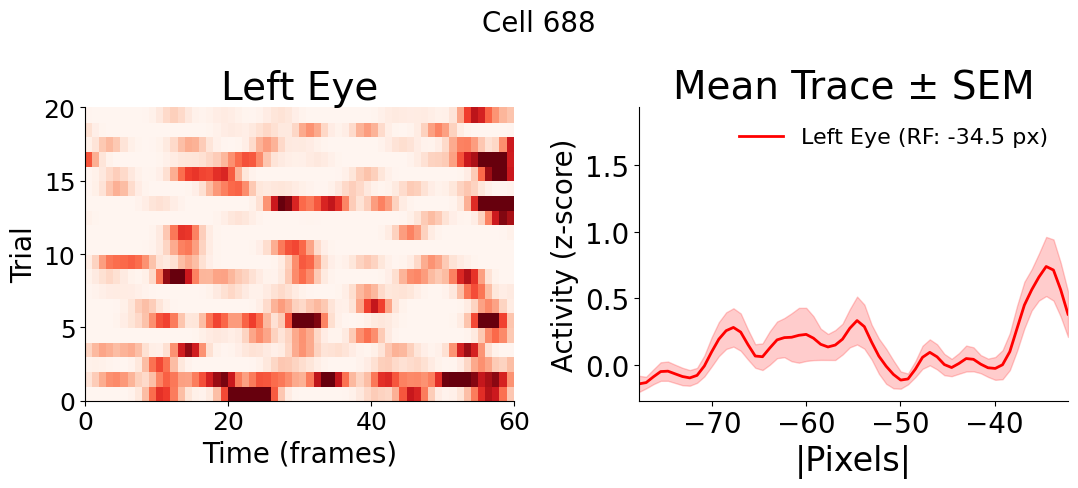

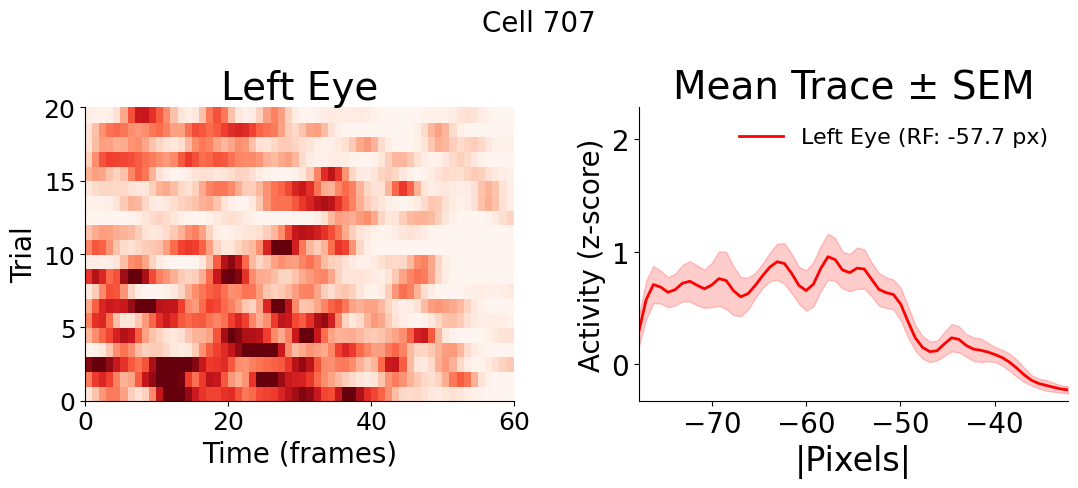

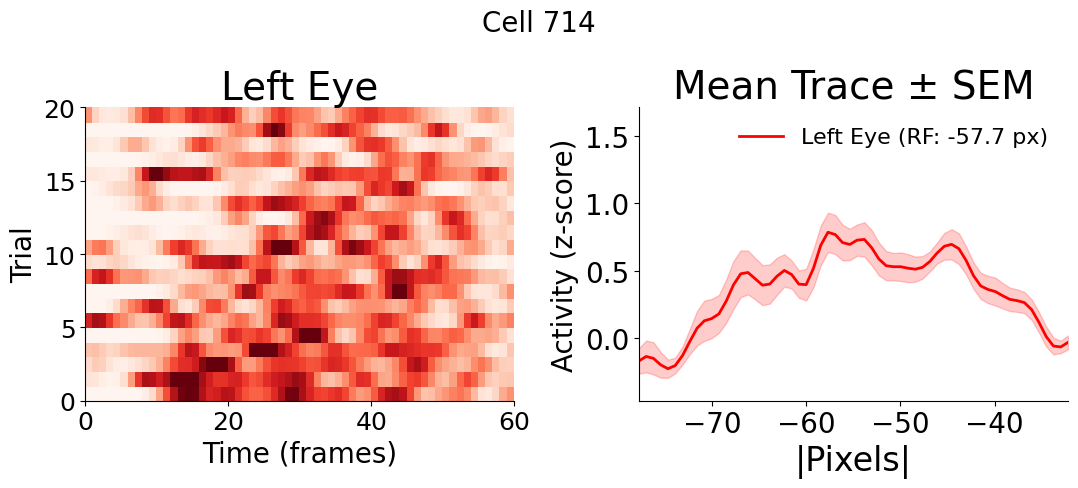

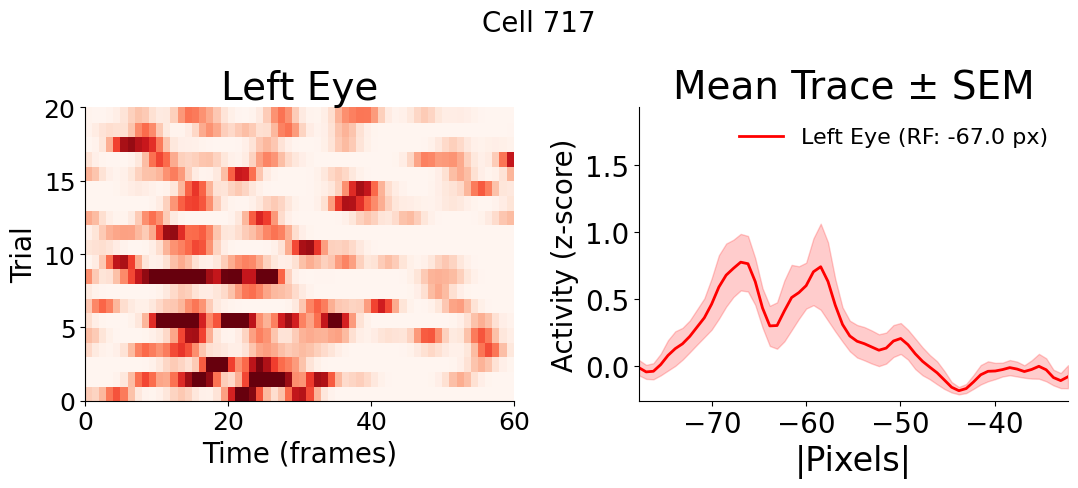

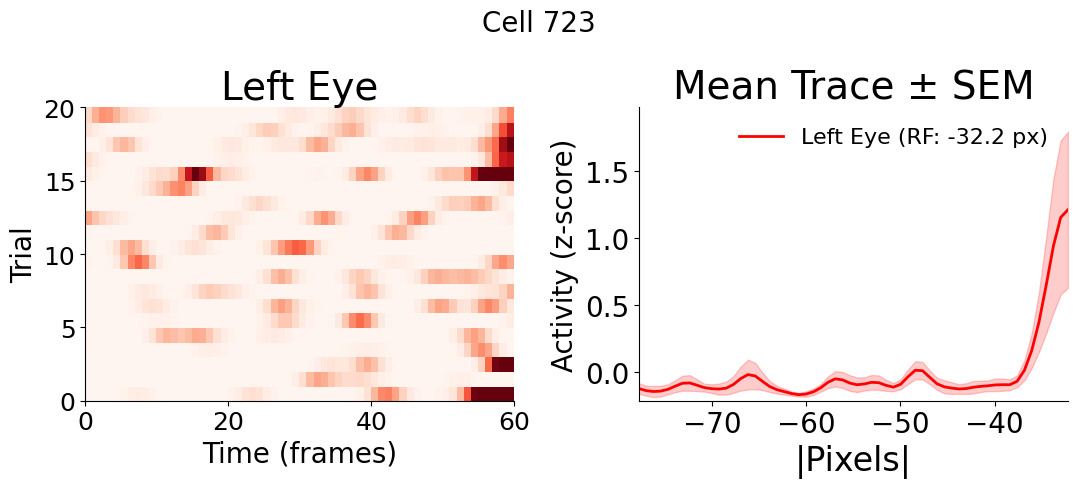

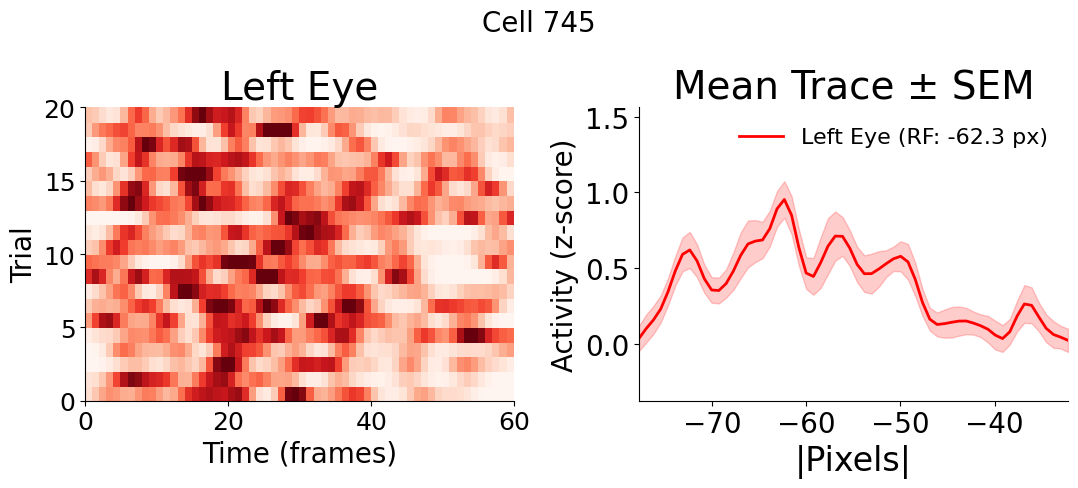

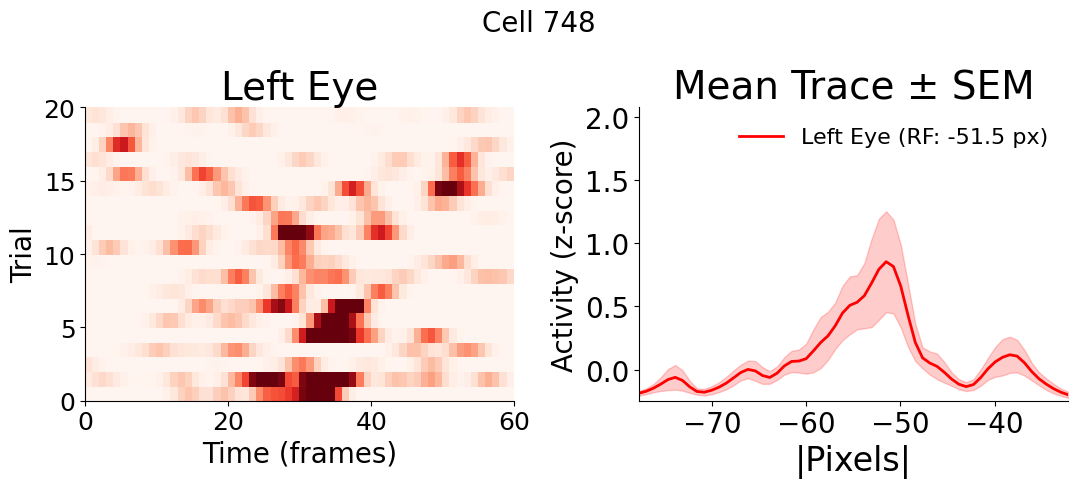

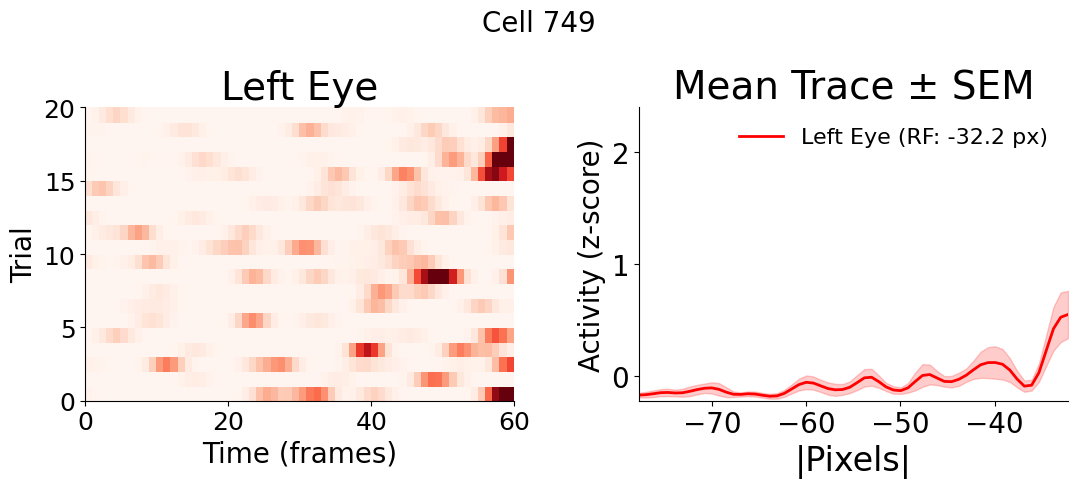

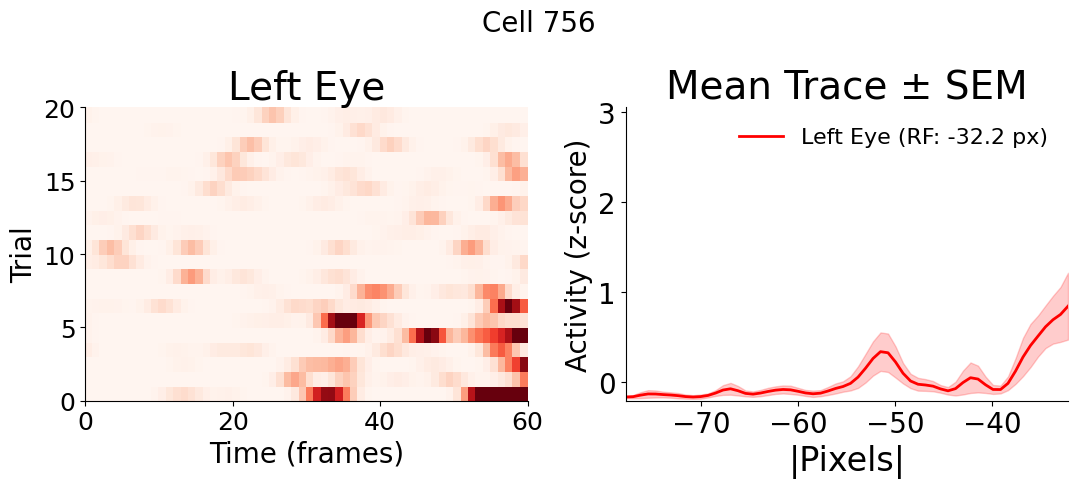

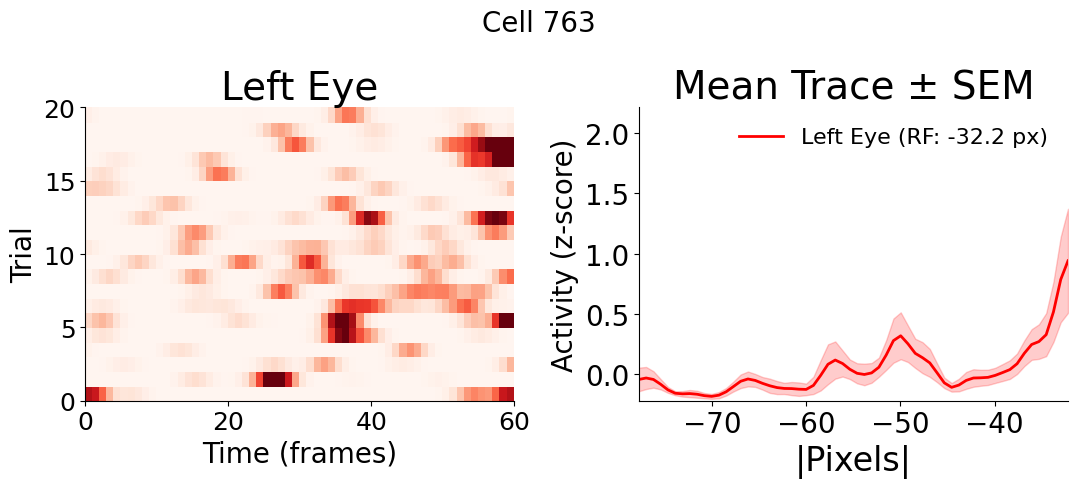

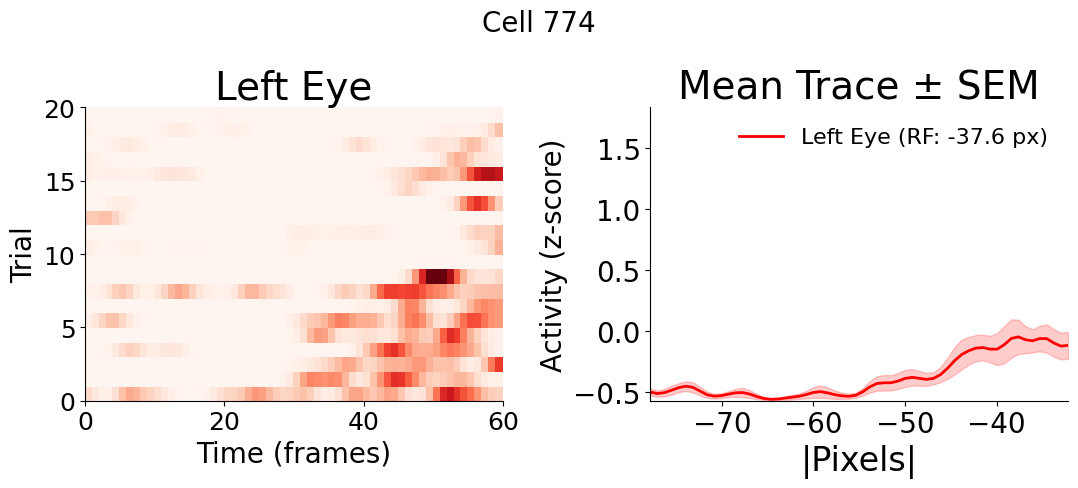

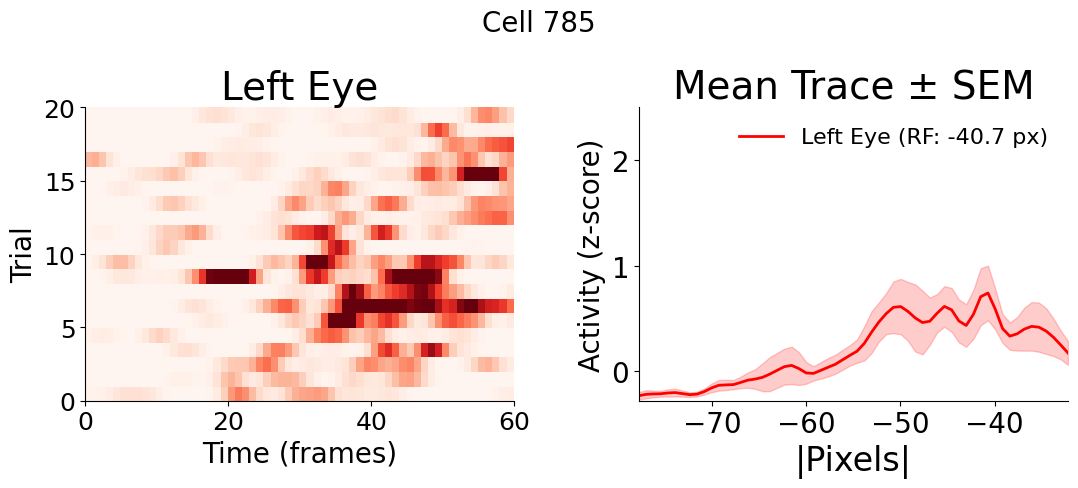

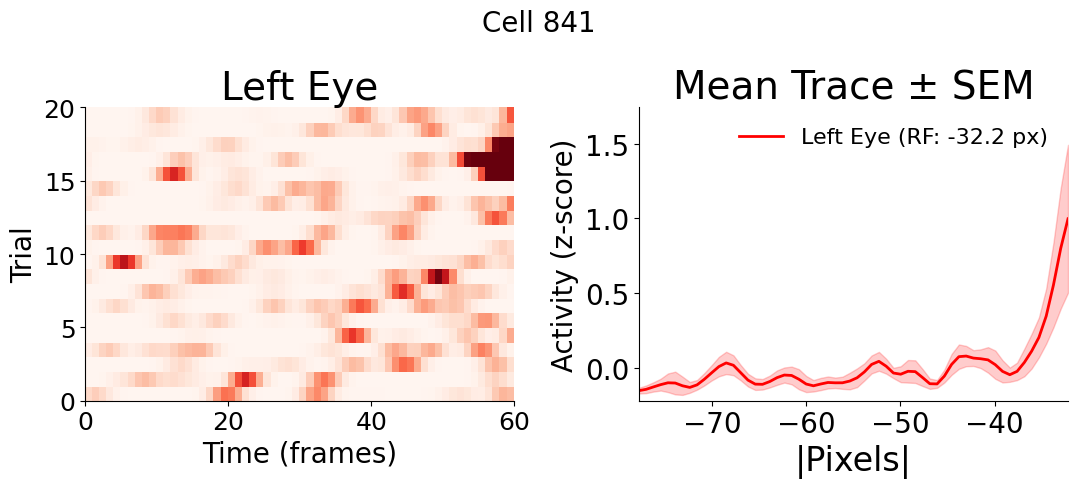

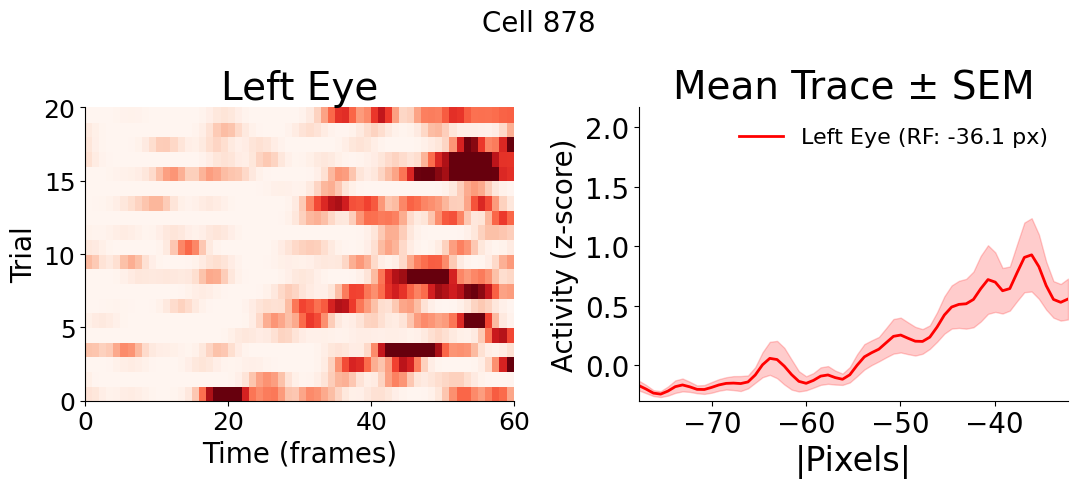

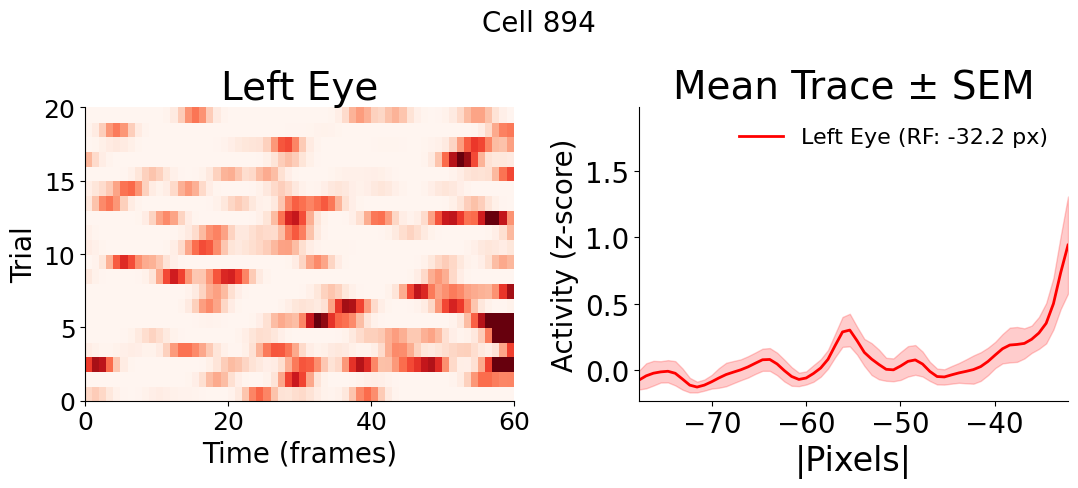

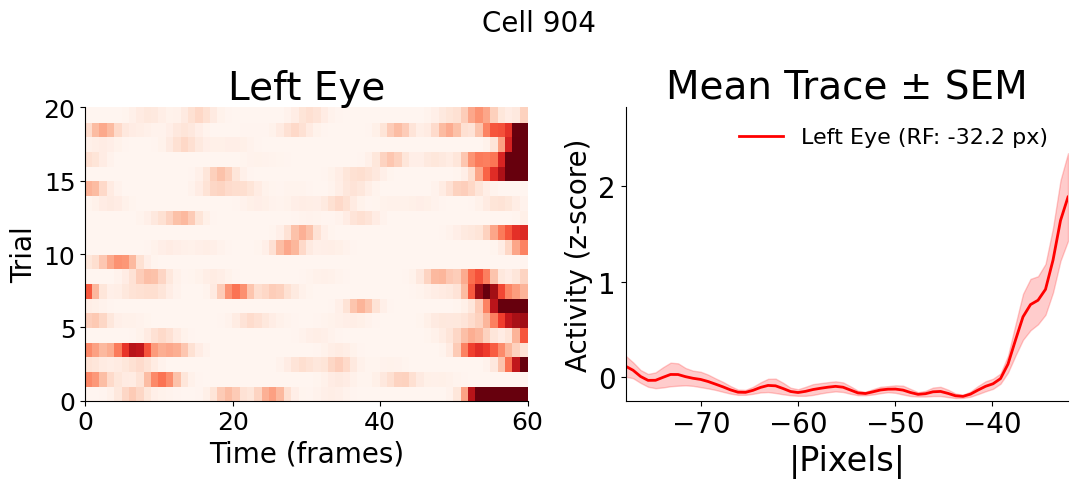

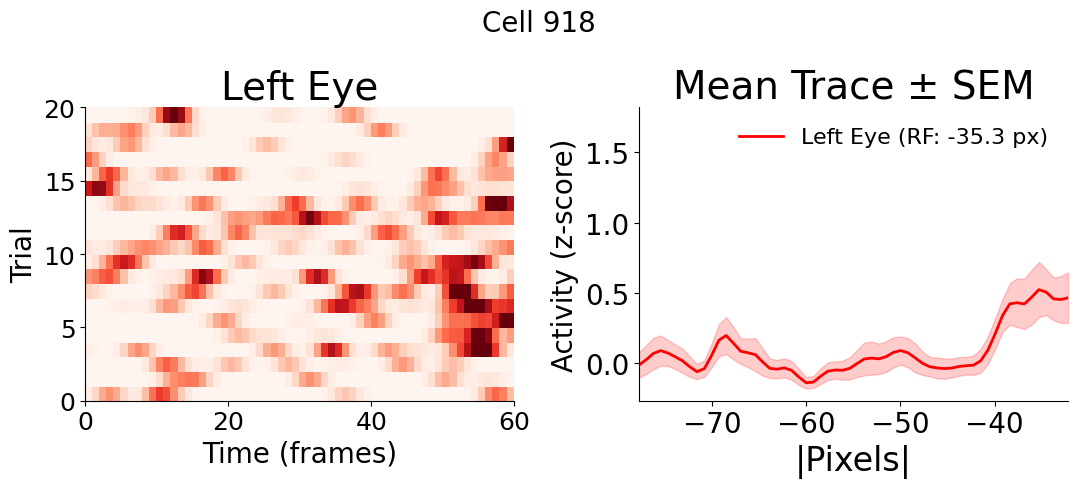

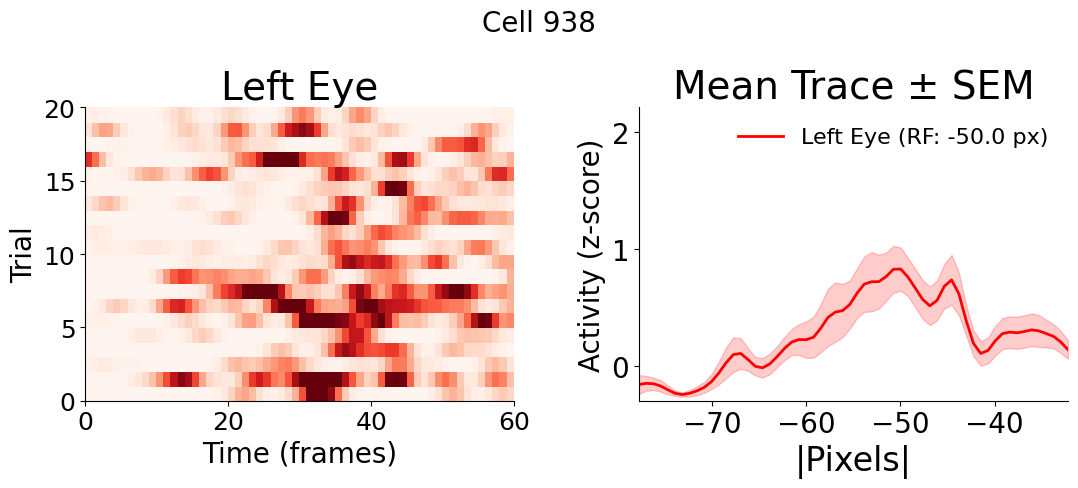

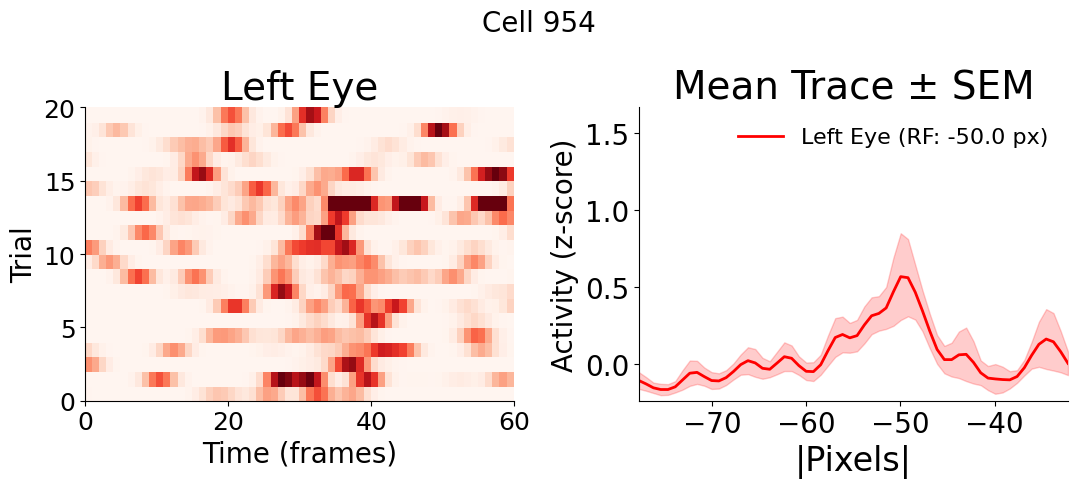

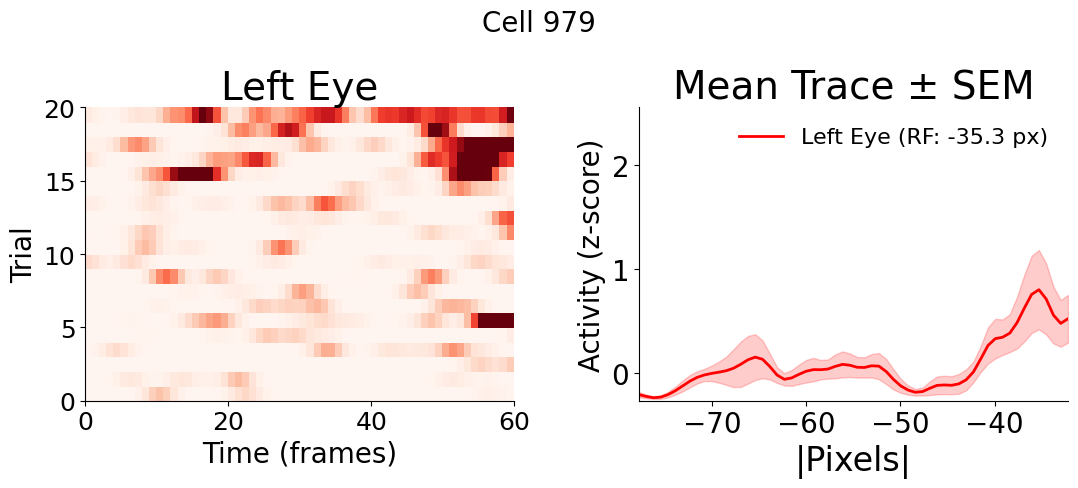

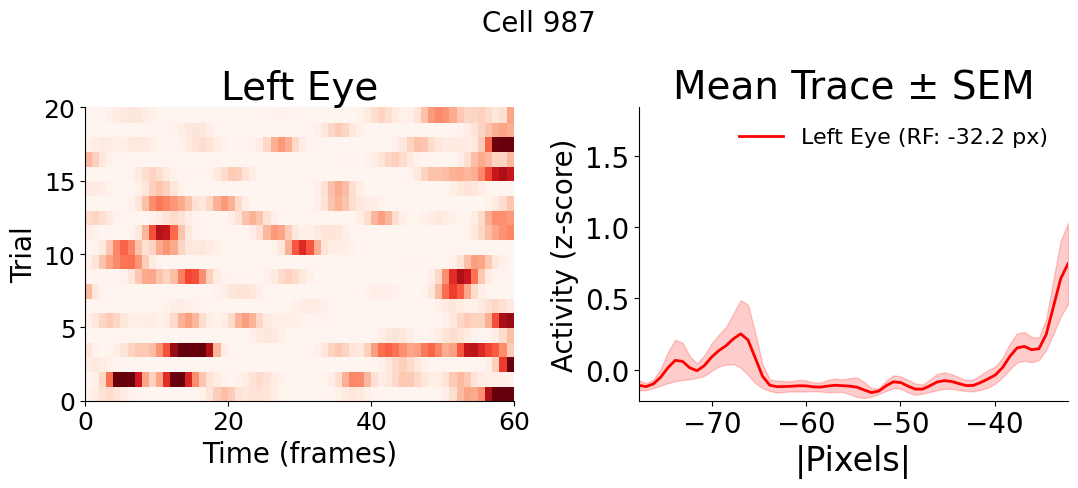

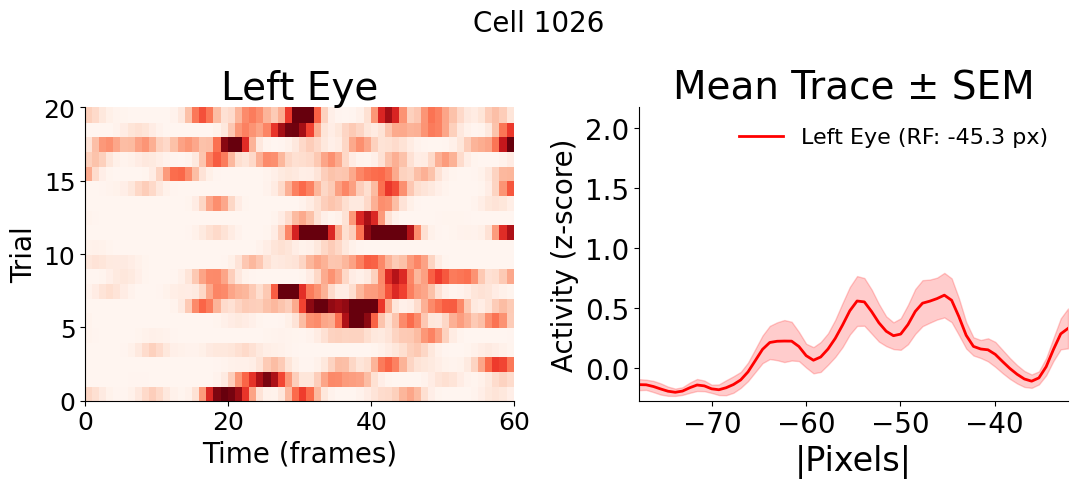

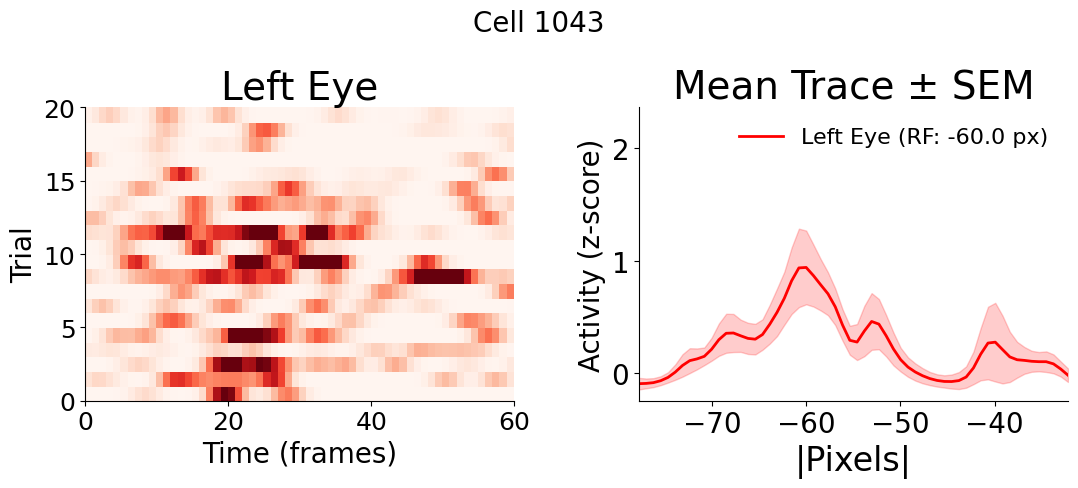

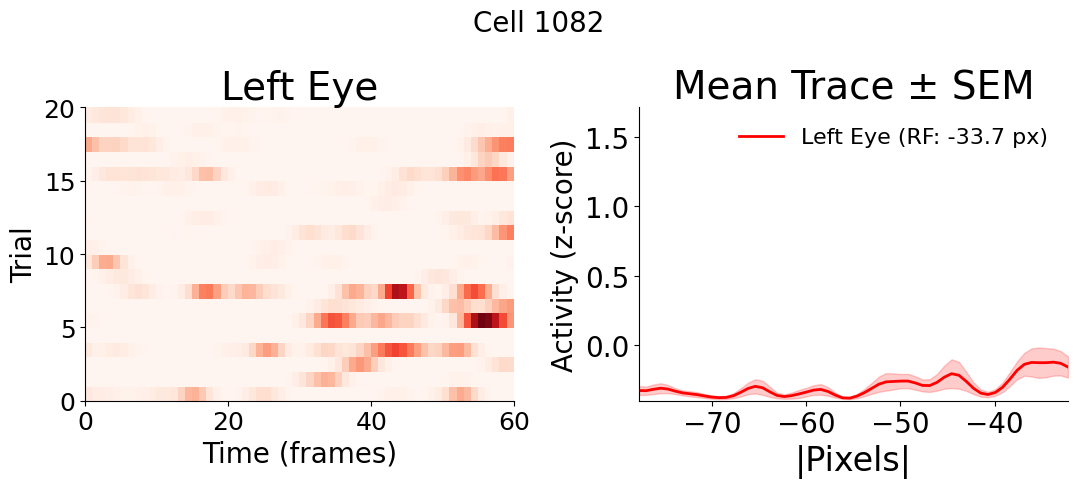

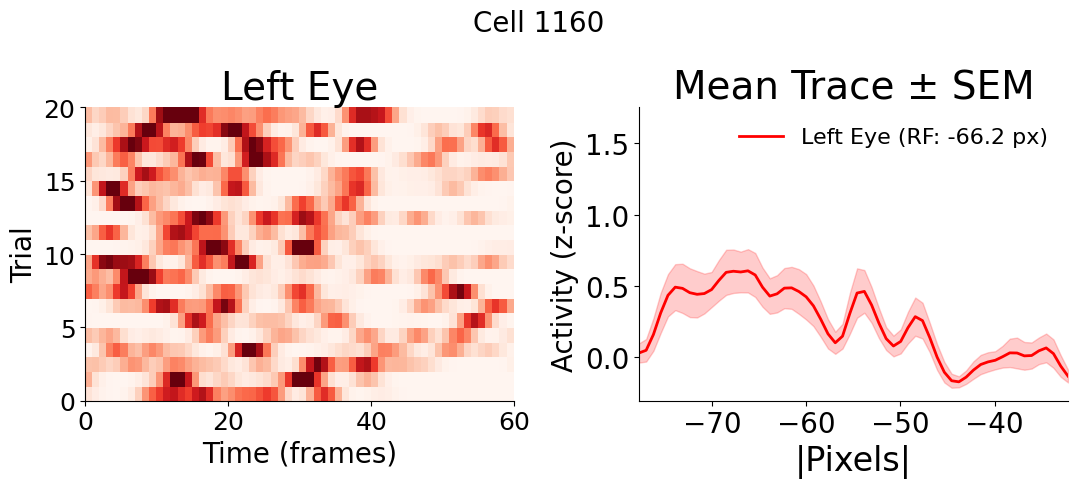

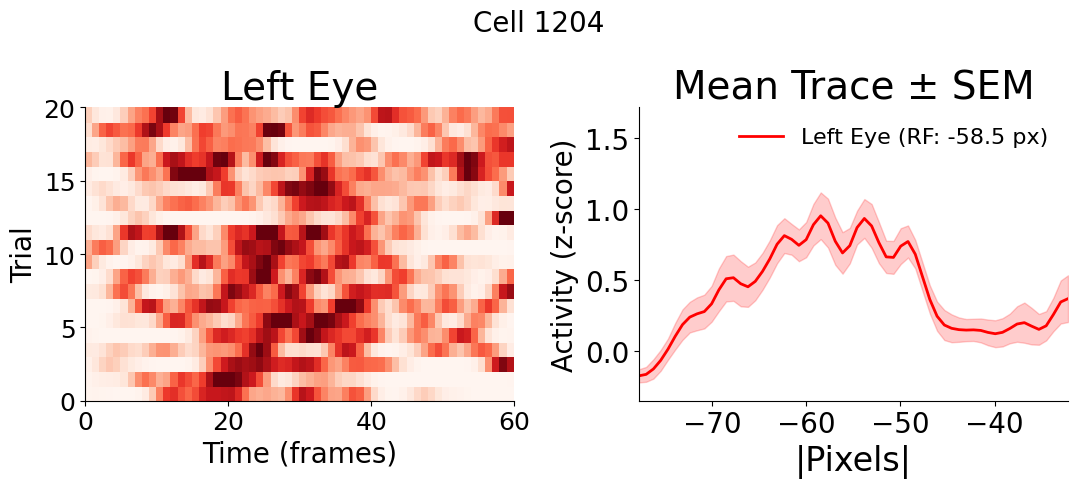

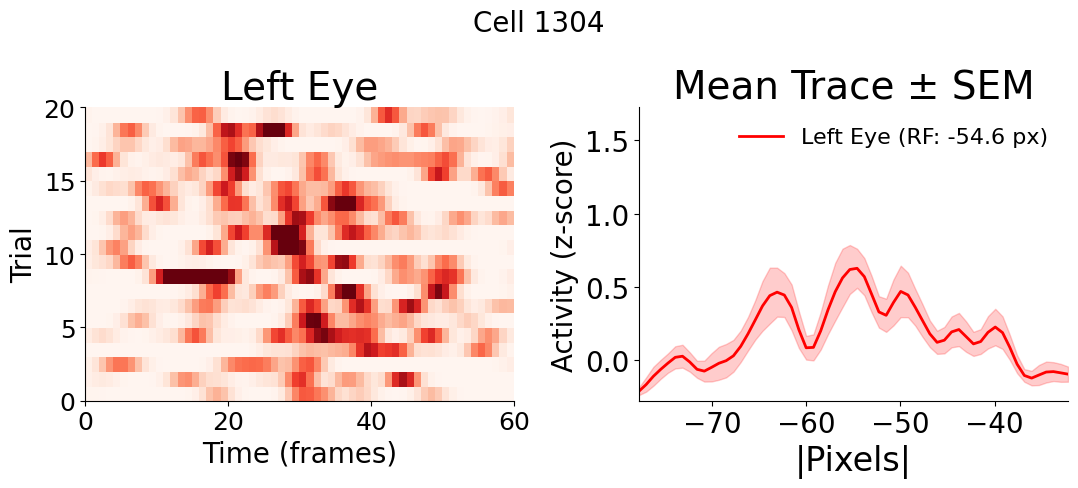

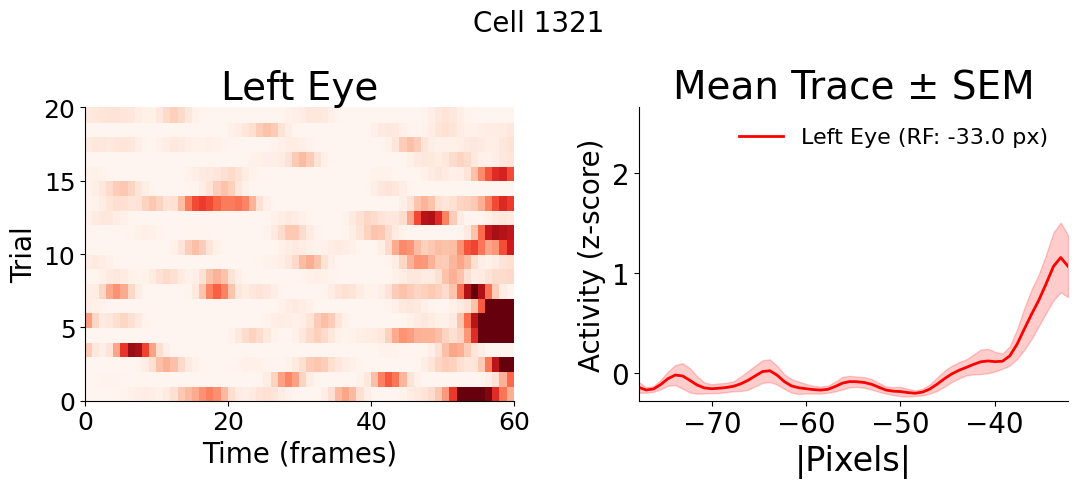

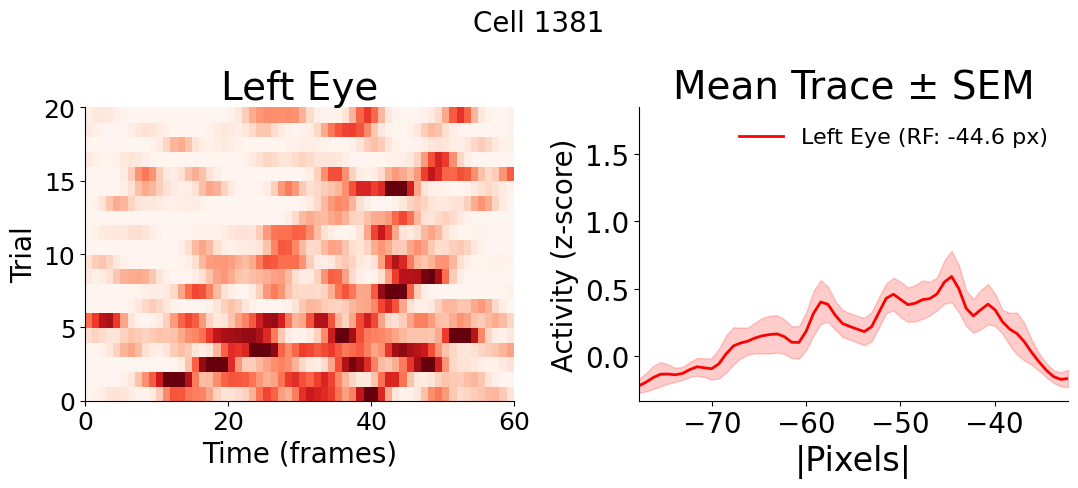

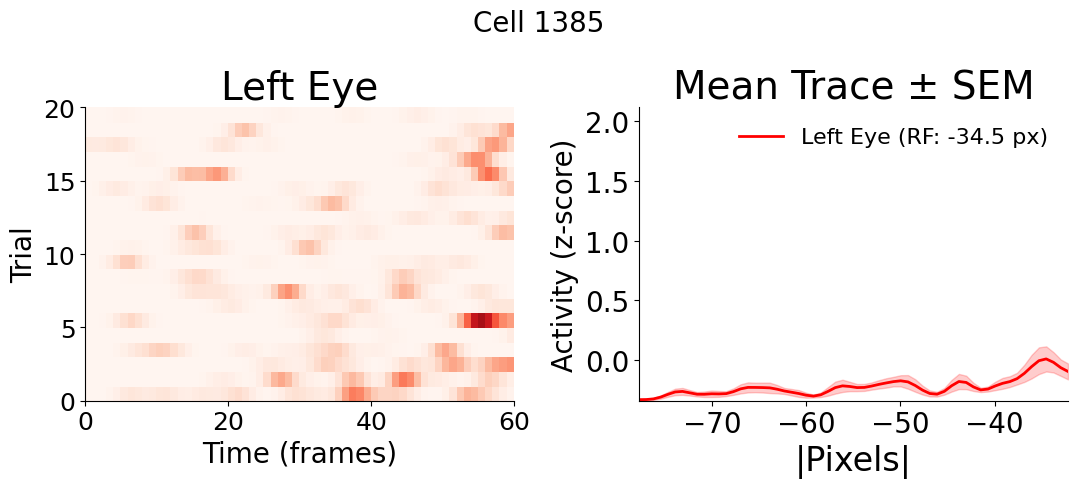

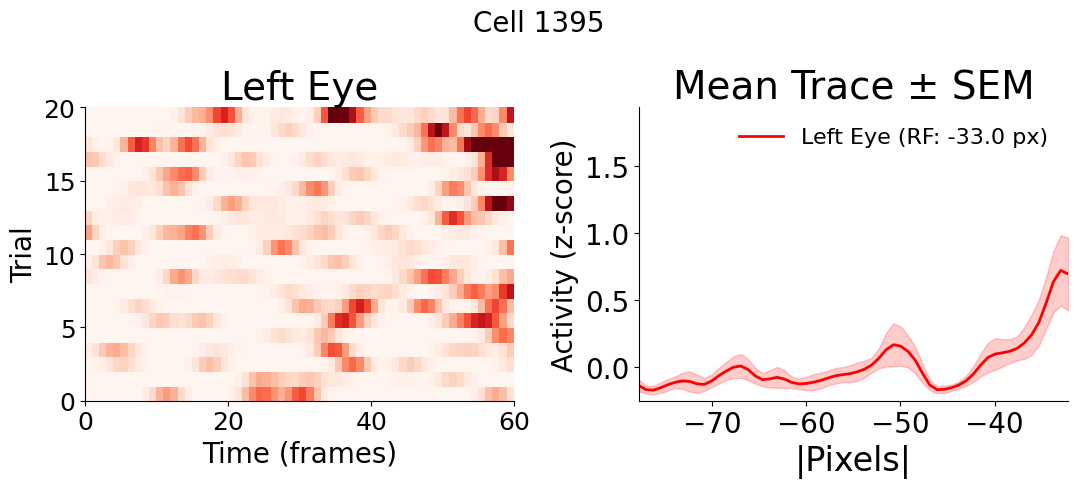

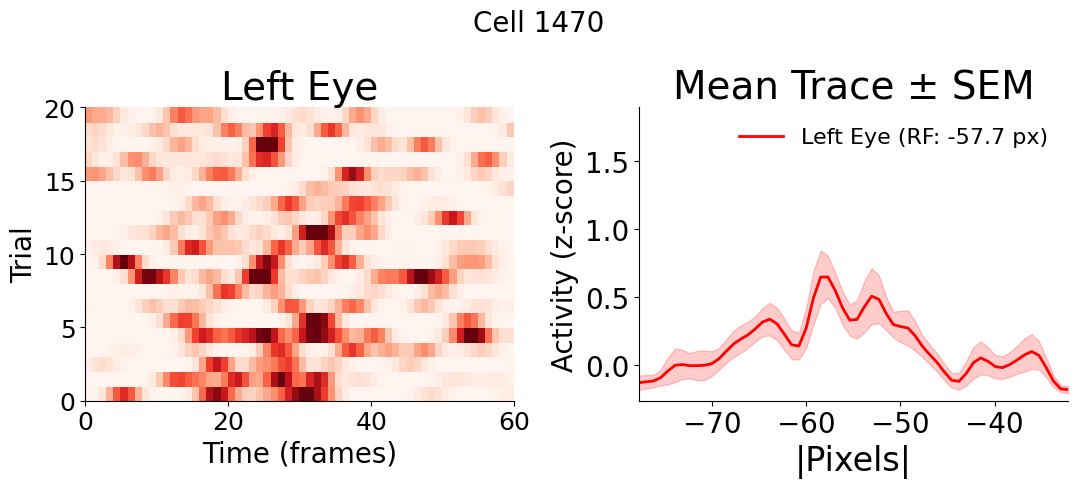

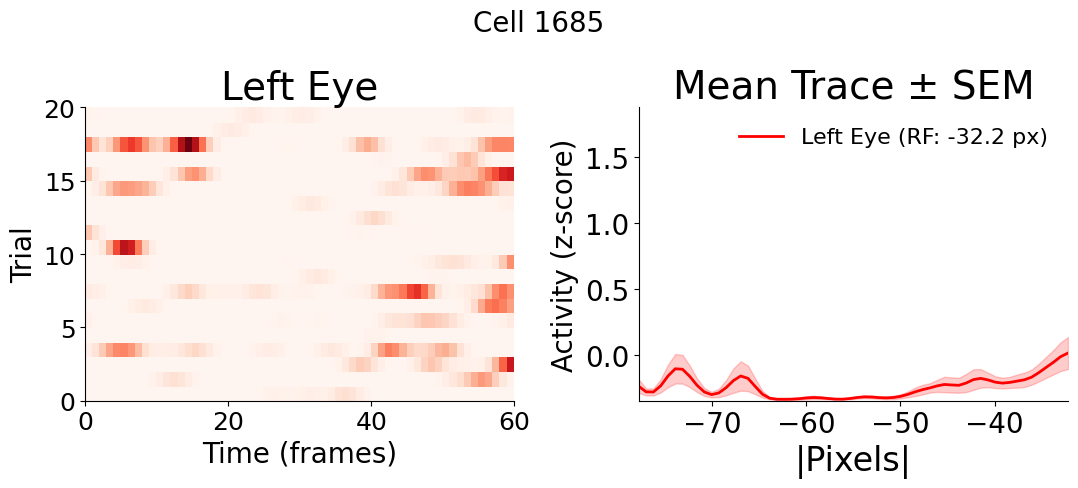

In [115]:
# response of every left-reliable cell (trial heatmap + mean +/- SEM tuning curve)
# For many cells this renders a lot of figures; to save them to disk instead use:
#   CellVisualizer(M).save_all_cells(kind="eye", eye="left")
viz = CellVisualizer(M)
for cell in left_reliable:
    viz.make_eye_plot(cell, eye="left")
    plt.show()

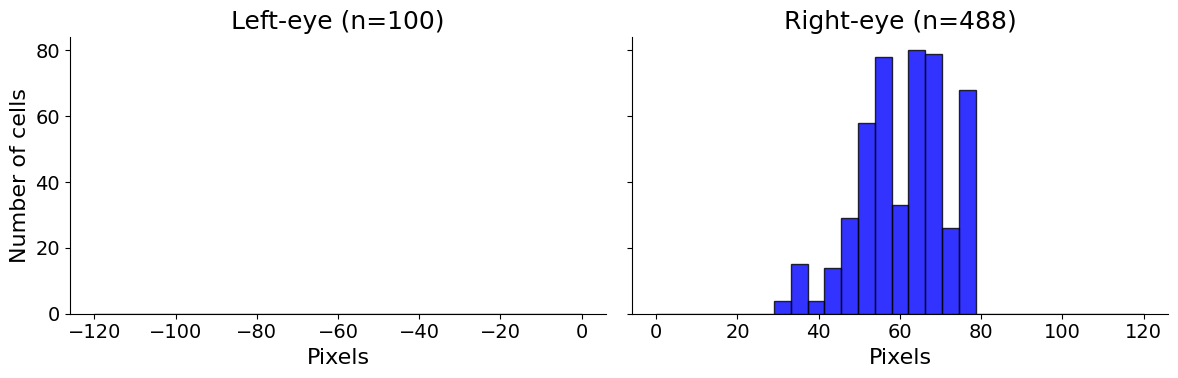

In [116]:
# histogram of reliable cells and their receptive-field position (px)
sv.plot_rf_histograms()
plt.show()

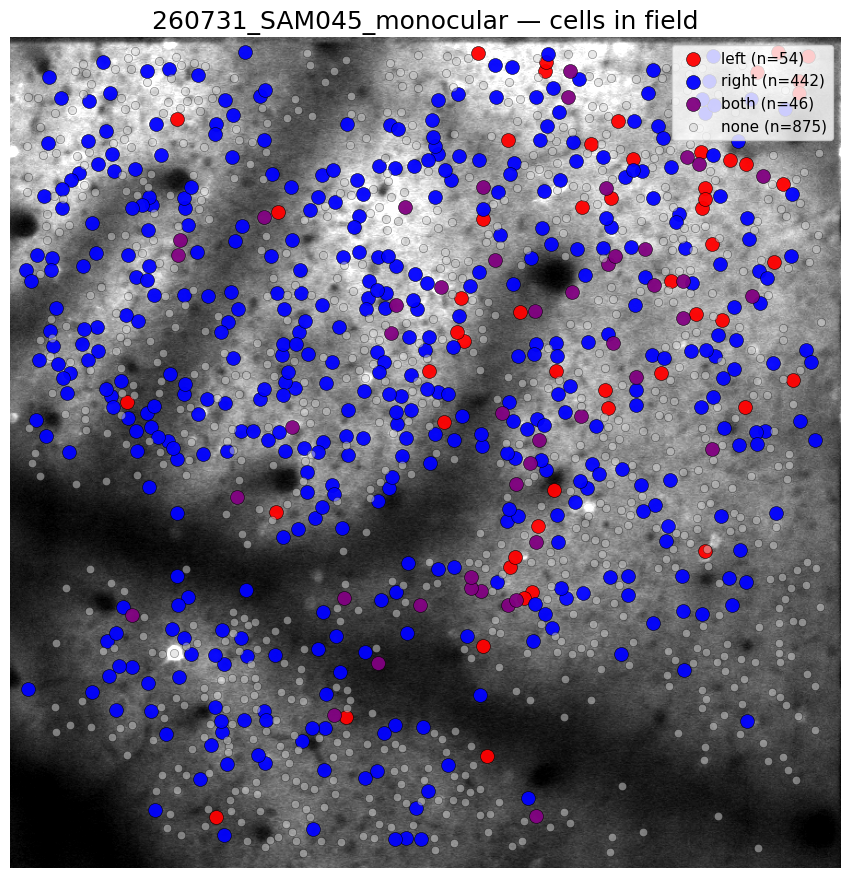

In [117]:
# reliable cells overlaid on the 2p field-of-view, rotated to match suite2p
fig = sv.plot_location_map(cell_size = 100)
ax = fig.axes[0]
ax.invert_xaxis()   # undo plot_location_map's radial-convention inversions...
ax.invert_yaxis()   # ...so the FOV matches the suite2p GUI orientation
plt.show()